# Thực Hành 1: So Sánh Logistic, MLP Và CNN Trên Fashion-MNIST (PyTorch)

Notebook thực thi khép kín và đồng bộ phân tích với báo cáo chính [`docs/REPORT.md`](docs/REPORT.md), so sánh 3 kiến trúc **Logistic Regression (7.850 tham số)**, **MLP (109.386 tham số)** và **CNN (105.866 tham số)** trên bài toán phân loại 10 lớp trang phục **Fashion-MNIST**. Chi tiết kỹ thuật từng pipeline đặt tách riêng tại [`docs/pipelines/README.md`](docs/pipelines/README.md).

- **Kết quả nổi bật**: `CNN (no_aug)` đạt Test Accuracy **91.13%** và Macro F1 **91.04%**, vượt `MLP` (+2.8 điểm %) và `Logistic` (+7.3 điểm %). `CNN` (105.866) và `MLP` (109.386) cùng bậc ~105k tham số, nhưng `CNN` vượt nhờ tích chập 2D; `Logistic` chỉ có 7.850 tham số làm baseline. Augmentation không cải thiện test metrics cho bất kỳ kiến trúc nào trong 20 epoch, và làm `Logistic` giảm 9.1 điểm % accuracy. `Shirt` là lớp khó nhất (F1 54.56–74.50% ở nhánh `no_aug`, xuống 44.08% ở `Logistic aug`) do tương đồng hình học với `T-shirt/top` và `Pullover`.

## Bảng Lộ Trình Thực Thi & Liên Kết Tài Liệu Kỹ Thuật

| Step | Description | What it does | Import path |
| :---: | :--- | :--- | :---: |
| `1` | Setup & Define | Khởi tạo môi trường, `seed = 248`, đặc tả bài toán và giả thuyết `H1–H3` | [`src/config.py`](../../../src/config.py) |
| `2` | Dataset: Collection, Cleaning & Splitting | Tải Fashion-MNIST, xác thực SHA-256 `manifest.json`, kiểm toán 6 chiều, tách tầng `55k / 5k / 10k` | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `3` | EDA (Three Lenses) | Khảo sát Lens 1 (Global), Lens 2 (Class Balance & Pixel Distribution), Lens 3 (Sample Grid, Prototypes, Cosine & PCA 2D) | [`src/vibe_scripts/eda_helpers.py`](../../../src/vibe_scripts/eda_helpers.py) |
| `4` | Data Processing (Pipe 01) | Chuẩn hóa Z-Score trên 55k Train (`0.2862`, `0.3531`), tách 2 nhánh `no_aug`/`aug`, dựng DataLoader | [`src/vibe_scripts/lab1/data.py`](../../../src/vibe_scripts/lab1/data.py) |
| `5` | Model Selection (Pipe 02) | Khởi tạo 3 kiến trúc `Logistic` (7.850), `MLP` (109.386), `CNN` (105.866) cùng đầu vào `[B, 1, 28, 28]` | [`src/vibe_scripts/lab1/models.py`](../../../src/vibe_scripts/lab1/models.py) |
| `6` | Baseline & Training (Pipe 03) | Sanity check Baseline `Logistic` và huấn luyện công bằng ma trận `3 × 2` (`Adam lr=1e-3`, `20 epochs`, `seed=248`) | [`src/vibe_scripts/lab1/train.py`](../../../src/vibe_scripts/lab1/train.py) |
| `7` | Evaluate (Pipe 04) | Đánh giá Test 1 lần trên `best.pt`, bảng Metric tổng hợp, Learning Curves, Per-class F1 & Kiểm tra `H1–H3` | [`src/vibe_scripts/lab1/evaluate.py`](../../../src/vibe_scripts/lab1/evaluate.py) |
| `8` | Error Analysis | Phân tích lỗi 3 bước (Confusion Matrix, Predictions Gallery, Nguyên nhân → Hành động) & Hạn chế/Kết luận | [`src/vibe_scripts/lab1/evaluate.py`](../../../src/vibe_scripts/lab1/evaluate.py) |
| `9` | Inference & Serving (Pipe 05) | Suy luận mẫu độc lập Top-3 Softmax và benchmark tốc độ (`batch_size = 1, 32`) | [`src/vibe_scripts/lab1/infer.py`](../../../src/vibe_scripts/lab1/infer.py) |

---

### Liên Kết Nhanh Tài Liệu & Báo Cáo Kỹ Thuật
- 📄 Báo Cáo Chính (Đồng Bộ Phân Tích): [`docs/REPORT.md`](docs/REPORT.md)
- 🧩 Đặc Tả Chi Tiết 5 Pipeline Kỹ Thuật: [`docs/pipelines/README.md`](docs/pipelines/README.md)
- 📋 Đề Bài & Yêu Cầu Gốc: [`docs/QUESTION.md`](docs/QUESTION.md)
- ⚙️ Cấu Hình Override Lab 1: [`config.py`](config.py)
- 📖 Tài Liệu Hướng Dẫn Dự Án: [`README.md`](../../../README.md)

## 1. Thiết Lập Môi Trường Thực Thi (Setup)

Khởi tạo cấu hình phần cứng, đường dẫn gốc và thư viện dùng chung (`seed = 248`) để bảo đảm tính tái lập thí nghiệm.

In [1]:
%matplotlib inline

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision.datasets import FashionMNIST
from torch.utils.data import Subset

from src import config, consoles
from src.vibe_scripts import eda_helpers

if str(config.ROOT_PATH) not in sys.path:
    sys.path.insert(0, str(config.ROOT_PATH))

consoles.creation()
v_objConsole = consoles.v_objConsole

                          Configuration                           
┌───────────────┬────────────────────────────────────────────────┐
│ Root          │ D:\notworLe\Desktop\gitvanhub\Deeplearning-UTH │
│ Version       │ 2.15.0+cu132                                   │
│ Device        │ cuda                                           │
│ GPU           │ NVIDIA GeForce RTX 4060 Laptop GPU             │
│ VRAM          │ 8.6 GB                                         │
│ Seed          │ 248                                            │
│ Workers       │ 8                                              │
│ Batch size    │ 32                                             │
│ Learning rate │ 1e-05                                          │
│ Epoch         │ 30                                             │
└───────────────┴────────────────────────────────────────────────┘

---
## 2. Define

### Define context
- **Name**: So sánh hiệu năng CNN, MLP, Logistic trên bài toán phân loại Fashion-MNIST bằng PyTorch.
- **Context**: Bài thực hành Deep Learning chuẩn hóa pipeline từ dữ liệu bất biến đến đánh giá và suy luận.
- **Target**:
  - **Main**: Làm chủ PyTorch qua quy trình huấn luyện deep learning.
  - **Extra**: Kiểm chứng định lượng tác động của kiến trúc không gian 2D (`CNN` vs `MLP` cùng bậc tham số) và kỹ thuật `Augmentation`.
- **Constraint**:
  - **Công bằng thí nghiệm**: Cả 3 mô hình dùng chung `CrossEntropyLoss`, `Adam`, `lr = 1e-3`, `batch_size = 32`, `epochs = 20`, tham số `Normalize(mean, std)` fit trên Train và `seed = 248`.
  - **Cùng bậc tham số**: `MLP` (`109.386`) và `CNN` (`105.866`) chênh nhau ~3,2% để cô lập ảnh hưởng của cấu trúc tích chập 2D.

### Define problem
- **Input**: Ảnh xám kích thước $28 \times 28$ (1 kênh màu), đối tượng thời trang căn giữa khung hình.
- **Output**: Dự đoán nhãn thuộc 10 lớp thời trang và báo cáo phân tích định lượng + phân tích lỗi.
- **Metrics**: Accuracy, Precision/Recall/F1 từng lớp, Confusion Matrix $10 \times 10$, số tham số, epoch hội tụ tốt nhất, kích thước checkpoint (KB) và độ trễ suy luận (ms).
- **Baseline**: `Logistic` (`7.850` tham số).
- **Experiments**: Ma trận 6 lần chạy (`{Logistic, MLP, CNN} × {no_aug, aug}`) với cùng `seed = 248`.

### Hypotheses

Các tiêu chí đo trên Test set, dùng để **báo cáo cuối cùng**; Test không được dùng để chọn cấu hình hay điều chỉnh mô hình.

| Giả thuyết | Dự đoán | Tiêu chí đúng / bác bỏ (đo trên Test, chỉ báo cáo) |
| :--- | :--- | :--- |
| **H1** — Kiến trúc 2D vượt trội *(pre-hoc)* | CNN > MLP > Logistic về Test Accuracy | Chênh lệch giữa mỗi cặp liền kề > 0.5 điểm % |
| **H2** — Augmentation cải thiện tổng quát hóa *(tiêu chí post-hoc)* | Cấu hình `aug` có Test Loss thấp hơn `no_aug` trên cùng kiến trúc | `test_loss(aug) < test_loss(no_aug)` cho ít nhất 2/3 kiến trúc |
| **H3** — Lỗi tập trung ở nhóm áo thân trên *(tiêu chí post-hoc)* | Các cặp nhầm lẫn lớn nhất thuộc nhóm `{T-shirt, Pullover, Coat, Shirt}` | ≥ 4 trong 5 cặp nhầm nhiều nhất nằm trong nhóm áo thân trên |

---
## 3. Dataset

### 3.1 Collection & Data Provenance
- **Source**: Zalando Research Fashion-MNIST tải qua `torchvision.datasets.FashionMNIST`, lưu trữ chỉ đọc tại `data/FashionMNIST/raw/`.
- **Data Provenance**: Ghép cặp `manifest.json` và `<file>.manifest.json`; xác thực SHA-256 phải đạt `[PASS]` 8/8 tệp nhị phân.
- **Metadata**: 70.000 ảnh gồm 60.000 train và 10.000 test, kích thước $28 \times 28$, thang giá trị pixel `0–255`.
- **Label names (10 lớp)**: `0 T-shirt/top`, `1 Trouser`, `2 Pullover`, `3 Dress`, `4 Coat`, `5 Sandal`, `6 Shirt`, `7 Sneaker`, `8 Bag`, `9 Ankle boot`.

In [2]:
raw_train = FashionMNIST(root=config.DATA_PATH, train=True, download=False)
raw_test  = FashionMNIST(root=config.DATA_PATH, train=False, download=False)

df_raw = pd.DataFrame(
    [
        ("Số lượng mẫu Train thô", f"{len(raw_train):,}"),
        ("Số lượng mẫu Test thô",  f"{len(raw_test):,}"),
        ("Kích thước ảnh mẫu",     f"{tuple(raw_train.data[0].shape)} (H x W)"),
        ("Kiểu dữ liệu gốc",       str(raw_train.data.dtype)),
        ("Số lớp",                 str(len(eda_helpers.FASHION_CLASSES))),
        ("Danh sách nhãn lớp",     ", ".join(eda_helpers.FASHION_CLASSES)),
    ],
    columns=["metric", "value"],
)
v_objConsole.print(consoles.df_to_table(df_raw, title="RAW DATASET OVERVIEW", show_header=False))

manifest_path = config.DATA_PATH / "FashionMNIST" / "raw" / "manifest.json"
manifest_data, verify_results = eda_helpers.load_and_verify_manifest(manifest_path)
eda_helpers.print_manifest_table(manifest_data, verify_results)

                                              RAW DATASET OVERVIEW                                               
┌────────────────────────┬──────────────────────────────────────────────────────────────────────────────────────┐
│ Số lượng mẫu Train thô │ 60,000                                                                               │
│ Số lượng mẫu Test thô  │ 10,000                                                                               │
│ Kích thước ảnh mẫu     │ (28, 28) (H x W)                                                                     │
│ Kiểu dữ liệu gốc       │ torch.uint8                                                                          │
│ Số lớp                 │ 10                                                                                   │
│ Danh sách nhãn lớp     │ T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot │
└────────────────────────┴──────────────────────────────────────────────────────────────────────────────────────┘
                                                 6 rows × 2 cols                                                 

                  DATA INGESTION MANIFEST (§3.2 PROVENANCE & GOVERNANCE)                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Property                 ┃ Specification / Value                                       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Dataset Name             │ fashion_mnist                                               │
│ Raw Storage Path         │ data/FashionMNIST/raw/train-images-idx3-ubyte.gz            │
│ Source URI               │ http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/ │
│ Collection Timestamp     │ 2026-11-15T19:13:57+07:00                                   │
│ Total Ingested Records   │ 70,000 samples                                              │
│ Collection Agent Version │ torchvision_v0.29.2+cu132                                   │
└──────────────────────────┴─────────────────────────────────────────────────────────────┘

                            CRYPTOGRAPHIC INTEGRITY VERIFICATION (SHA-256)                            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓
┃ Artifact File              ┃     Size ┃ Expected SHA-256        ┃ Verified SHA-256        ┃ Status ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩
│ train-images-idx3-ubyte.gz │ 26.42 MB │ 3aede38d61863908ad78... │ 3aede38d61863908ad78... │ [PASS] │
│ train-labels-idx1-ubyte.gz │  29.5 KB │ a04f17134ac03560a47e... │ a04f17134ac03560a47e... │ [PASS] │
│ t10k-images-idx3-ubyte.gz  │  4.42 MB │ 346e55b948d973a97e58... │ 346e55b948d973a97e58... │ [PASS] │
│ t10k-labels-idx1-ubyte.gz  │   5.1 KB │ 67da17c76eaffca5446c... │ 67da17c76eaffca5446c... │ [PASS] │
│ train-images-idx3-ubyte    │ 47.04 MB │ c59f468a2f672dc81568... │ c59f468a2f672dc81568... │ [PASS] │
│ train-labels-idx1-ubyte    │  60.0 KB │ bad3541b69d912435c50... │ bad3541b69d912435c50... │ [PASS] │
│ t10k-images-idx3-ubyte     │  7.84 MB │ 5b4141f0afbad91edebe... │ 5b4141f0afbad91edebe... │ [PASS] │
│ t10k-labels-idx1-ubyte     │  10.0 KB │ 0402a96d92fd26639571... │ 0402a96d92fd26639571... │ [PASS] │
└────────────────────────────┴──────────┴─────────────────────────┴─────────────────────────┴────────┘

### 3.2 Cleaning (Kiểm toán chất lượng 6 chiều)

Kiểm toán Completeness, Accuracy, Consistency, Timeliness, Uniqueness và Validity trước khi tách tập.

In [3]:
audit_results = eda_helpers.audit_six_dimensions(
    raw_train.data, raw_train.targets,
    raw_test.data, raw_test.targets,
)
eda_helpers.print_audit_table(audit_results)
print(f"Kết luận kiểm toán: Completeness {audit_results['completeness_pct']:.1f}%, {audit_results['null_count']} NaN, pixel [{audit_results['pixel_min']}, {audit_results['pixel_max']}], 10 lớp đầy đủ → bỏ qua bước Data Cleaning.")

                           Data Quality Audit (6 Dimensions - CRISP-DM / §4)                           
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ Dimension          ┃ Verification Check                   ┃ Metric / Status        ┃ Assessment     ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ 1. Completeness    │ Null / Missing value scan across     │ Missing: 0 (100.0%)    │ [PASS] Clean   │
│                    │ tensors                              │                        │                │
│ 2. Accuracy        │ Physical pixel domain conformity [0, │ Range: [0, 255]        │ [PASS] Valid   │
│                    │ 255]                                 │                        │                │
│ 3. Consistency     │ Target classes domain integrity      │ 10 Classes (0-9)       │ [PASS]         │
│                    │                                      │                        │ Consistent     │
│ 4. Timeliness      │ Benchmark dataset currency &         │ Zalando Research       │ [PASS] Static  │
│                    │ immutability                         │ (Fixed)                │                │
│ 5. Uniqueness      │ Entity deduplication & record        │ Total: 70,000 samples  │ [PASS] Unique  │
│                    │ linkage                              │                        │                │
│ 6. Validity        │ Tensor geometric layout (N, 28, 28)  │ Shape: (28, 28), 1 Ch  │ [PASS] Valid   │
└────────────────────┴──────────────────────────────────────┴────────────────────────┴────────────────┘

Kết luận kiểm toán: Completeness 100.0%, 0 NaN, pixel [0, 255], 10 lớp đầy đủ → bỏ qua bước Data Cleaning.


### 3.3 Splitting

| Tập dữ liệu | Số lượng | Ghi chú |
| :--- | :---: | :--- |
| **Train** | `55.000` | Tách phân tầng (`stratified split`) từ 60k gốc với `seed = 248` (`5.500` mẫu/lớp) |
| **Validation** | `5.000` | Dùng theo dõi hội tụ và chọn `best.pt`, tách biệt hoàn toàn khỏi Train (`500` mẫu/lớp) |
| **Test** | `10.000` | Tập chuẩn Zalando cố định, chỉ đánh giá 1 lần cuối cùng (`1.000` mẫu/lớp) |

In [4]:
train_indices, val_indices = eda_helpers.stratified_split_indices(
    raw_train.targets.numpy(),
    train_size=55000,
    val_size=5000,
    seed=config.SEED,
)

train_dataset = Subset(raw_train, train_indices)
val_dataset   = Subset(raw_train, val_indices)
test_dataset  = raw_test

# Tách riêng tensor 55k Train để thực hiện EDA Lens 2 & Lens 3 không rò rỉ dữ liệu Validation
train_imgs = raw_train.data[train_indices]
train_tgts = raw_train.targets[train_indices]

splits = pd.DataFrame(
    [
        ("Train Set", len(train_dataset)),
        ("Validation Set", len(val_dataset)),
        ("Test Set", len(test_dataset)),
    ],
    columns=["split", "samples"],
)
v_objConsole.print(consoles.df_to_table(splits, title="DATASET SPLITTING (STRATIFIED, SEED=248)", show_header=False))

    DATASET SPLITTING     
  (STRATIFIED, SEED=248)  
┌────────────────┬───────┐
│ Train Set      │ 55000 │
│ Validation Set │  5000 │
│ Test Set       │ 10000 │
└────────────────┴───────┘
     3 rows × 2 cols      

### 3.4 EDA (Three Lenses)

Khảo sát theo mô hình 3 Thấu kính (tham chiếu [`docs/references/ML_PIPELINE.md`](../../../docs/references/ML_PIPELINE.md)): **Lens 1** (Global Structure) → **Lens 2** (Univariate Distributions) → **Lens 3** (Visual & Class Separability).

#### Lens 1: Global Structure

In [5]:
train_data_tensor = raw_train.data
test_data_tensor  = raw_test.data

train_memory_mib = (train_data_tensor.element_size() * train_data_tensor.nelement()) / (1024 ** 2)
test_memory_mib  = (test_data_tensor.element_size() * test_data_tensor.nelement()) / (1024 ** 2)
H, W = train_data_tensor.shape[-2:]

df_audit = pd.DataFrame(
    [
        ("Train Tensor Shape",     f"{tuple(train_data_tensor.shape)} (N_samples, H, W)"),
        ("Test Tensor Shape",      f"{tuple(test_data_tensor.shape)} (N_samples, H, W)"),
        ("Storage Data Type",      str(train_data_tensor.dtype)),
        ("Train Memory Footprint", f"{train_memory_mib:.2f} MiB"),
        ("Test Memory Footprint",  f"{test_memory_mib:.2f} MiB"),
        ("Tổng số điểm ảnh/ảnh",   f"{H * W} pixels ({H}×{W}, 1 kênh)"),
        ("Tổng số chiều quan sát", f"{train_data_tensor.ndim} chiều"),
    ],
    columns=["metric", "value"],
)
v_objConsole.print(consoles.df_to_table(df_audit, title="LENS 1: GLOBAL TOPOLOGY AUDIT", show_header=False))

                LENS 1: GLOBAL TOPOLOGY AUDIT                 
┌────────────────────────┬───────────────────────────────────┐
│ Train Tensor Shape     │ (60000, 28, 28) (N_samples, H, W) │
│ Test Tensor Shape      │ (10000, 28, 28) (N_samples, H, W) │
│ Storage Data Type      │ torch.uint8                       │
│ Train Memory Footprint │ 44.86 MiB                         │
│ Test Memory Footprint  │ 7.48 MiB                          │
│ Tổng số điểm ảnh/ảnh   │ 784 pixels (28×28, 1 kênh)        │
│ Tổng số chiều quan sát │ 3 chiều                           │
└────────────────────────┴───────────────────────────────────┘
                       7 rows × 2 cols                        

- **Kích thước & hình học tensor**: tập gốc gồm `raw_train` `(60.000, 28, 28)` và `raw_test` `(10.000, 28, 28)` (tổng `70.000` ảnh xám 1 kênh, mỗi ảnh $28 \times 28 = 784$ pixel). Toàn bộ mẫu đồng nhất kích thước nên không cần bước resize hay crop.
- **Kiểu dữ liệu & bộ nhớ**: lưu dưới dạng `torch.uint8` chiếm **44.86 MiB** (`raw_train`) và **7.48 MiB** (`raw_test`), tổng ~52.34 MiB — đủ nhỏ để nạp trọn vào RAM nhằm loại bỏ nút thắt I/O đĩa khi huấn luyện.
- **Tính toàn vẹn**: `0` giá trị khuyết (`NaN`/Null, completeness `100%`), miền pixel nằm đúng đoạn `[0, 255]`, nhãn lớp đầy đủ và nhất quán `{0..9}` → xác nhận dữ liệu thô sạch, không cần Data Cleaning.

#### Lens 2: Univariate Distributions *(thống kê cường độ pixel tính trên 55.000 mẫu Train)*

**1. Phân bố số lượng mẫu theo lớp (Train / Validation / Test)**

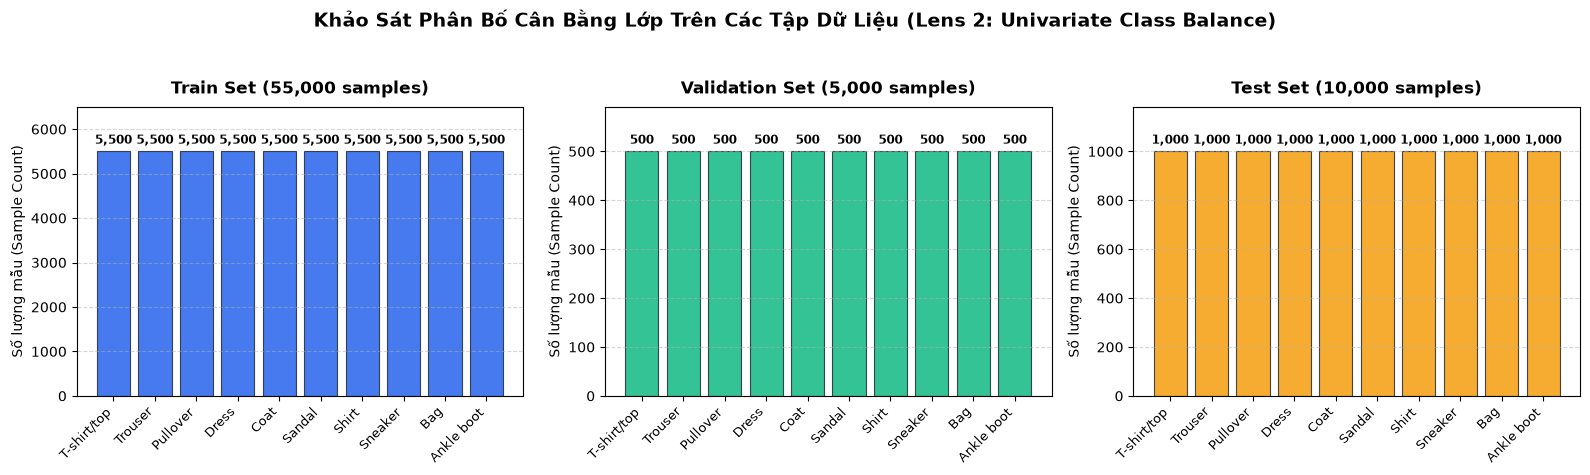

In [6]:
train_targets_arr = train_tgts.numpy()
val_targets_arr   = raw_train.targets[val_indices].numpy()
test_targets_arr  = raw_test.targets.numpy()

fig_balance = eda_helpers.plot_class_balance(train_targets_arr, val_targets_arr, test_targets_arr)
plt.show()

- Cân bằng lớp tuyệt đối ở cả 3 tập (`5.500 / 500 / 1.000` mẫu cho mỗi lớp trong 10 lớp) → loại bỏ hoàn toàn nguy cơ thiên vị lớp, đồng thời giải thích vì sao `Macro F1` luôn rất sát `Test Accuracy` ở bước đánh giá.

**2. Phân bố cường độ điểm ảnh (Toàn dải `[0, 255]` & Tiền cảnh `> 0`)**

                LENS 2: PIXEL DISTRIBUTION (55,000 TRAIN SAMPLES)                
┌────────────────────────────┬────────────────┬─────────────────────────────────┐
│ Giá trị Trung bình (Mean)  │ 72.97          │ thang 0-255 → chuẩn hóa: 0.2862 │
│ Độ lệch chuẩn (Std)        │ 90.04          │ thang 0-255 → chuẩn hóa: 0.3531 │
│ Trung vị (Median)          │ 0.0            │ do > 50% là nền đen (= 0)       │
│ Hệ số Bất đối xứng (Skew)  │ 0.694          │ lệch phải mạnh                  │
│ Độ nhọn (Kurtosis)         │ -1.192         │                                 │
│ Tỷ lệ Điểm ảnh Nền (= 0)   │ 50.21%         │ trên 43,12 triệu pixel Train    │
│ Tiền cảnh (> 0) Mean / Med │ 146.55 / 164.0 │ tập trung vùng sáng 190-230     │
└────────────────────────────┴────────────────┴─────────────────────────────────┘
                                 7 rows × 3 cols                                 

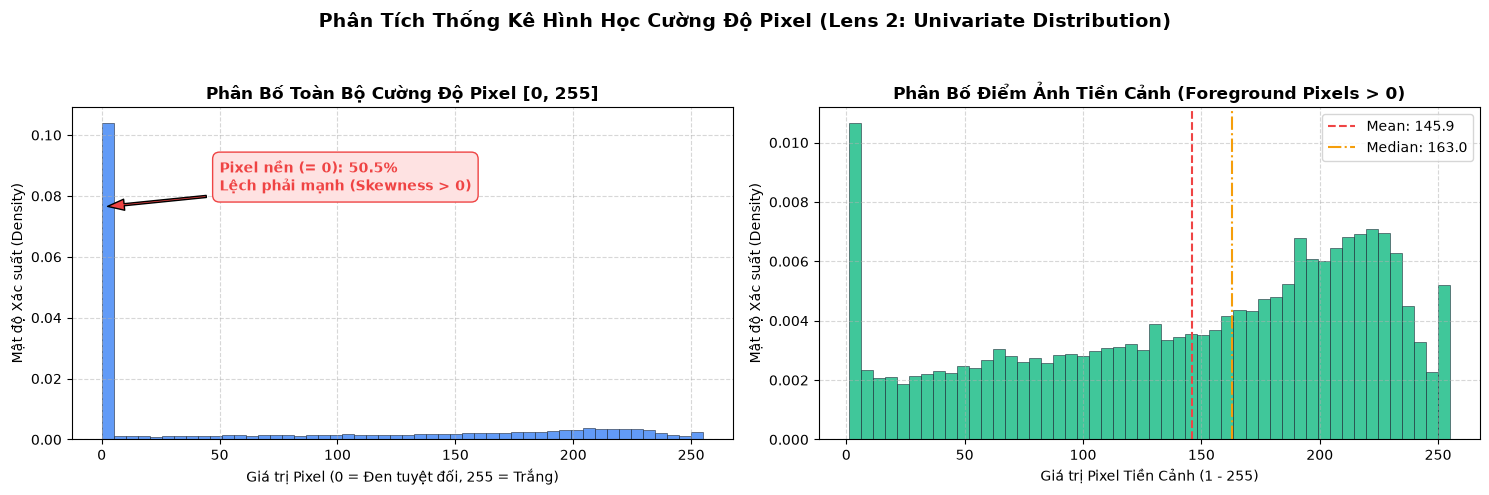

In [7]:
pixel_stats = eda_helpers.compute_pixel_statistics(train_imgs)
fg_pixels_all = train_imgs.numpy().astype(np.float32)
fg_pixels_all = fg_pixels_all[fg_pixels_all > 0]

df_stats = pd.DataFrame(
    [
        ("Giá trị Trung bình (Mean)", f"{pixel_stats['mean']:.2f}", f"thang 0-255 → chuẩn hóa: {pixel_stats['mean'] / 255:.4f}"),
        ("Độ lệch chuẩn (Std)",       f"{pixel_stats['std']:.2f}",  f"thang 0-255 → chuẩn hóa: {pixel_stats['std'] / 255:.4f}"),
        ("Trung vị (Median)",         f"{pixel_stats['median']:.1f}", "do > 50% là nền đen (= 0)"),
        ("Hệ số Bất đối xứng (Skew)", f"{pixel_stats['skewness']:.3f}", "lệch phải mạnh"),
        ("Độ nhọn (Kurtosis)",        f"{pixel_stats['kurtosis']:.3f}", ""),
        ("Tỷ lệ Điểm ảnh Nền (= 0)",  f"{pixel_stats['sparsity_zero_pct']:.2f}%", "trên 43,12 triệu pixel Train"),
        ("Tiền cảnh (> 0) Mean / Med", f"{fg_pixels_all.mean():.2f} / {np.median(fg_pixels_all):.1f}", "tập trung vùng sáng 190-230"),
    ],
    columns=["metric", "value", "note"],
)
v_objConsole.print(consoles.df_to_table(df_stats, title="LENS 2: PIXEL DISTRIBUTION (55,000 TRAIN SAMPLES)", show_header=False))

np.random.seed(config.SEED)
fig_pixel_dist = eda_helpers.plot_pixel_distribution_analysis(train_imgs.numpy())
plt.show()

- **Toàn dải `[0, 255]`** *(trên toàn bộ 55.000 mẫu Train = 43,12 triệu pixel)*: điểm ảnh nền bằng `0` chiếm **50.21%** (trung vị `median = 0`), kéo phân bố lệch phải mạnh (`skewness = 0.694`, `kurtosis = -1.192`), với giá trị trung bình $72.97 / 255 \approx 0.2862$ và độ lệch chuẩn $90.04 / 255 \approx 0.3531$.
- **Tiền cảnh (`pixel > 0`)**: khi tách riêng nền đen, mật độ điểm ảnh vật thể trải rộng với đỉnh tập trung ở vùng sáng `190–230` (trên toàn 55k Train: `mean = 146.55`, `median = 164.0`), kèm một cụm nhỏ sát biên `1–5` từ các pixel viền chống răng cưa. *(Ghi chú: đồ thị trên lấy mẫu ngẫu nhiên 100.000 pixel với `seed = 248`, nên hiển thị `50.5%` nền và tiền cảnh `mean 145.9 / median 163.0`, sai lệch nhẹ do lấy mẫu.)*

#### Lens 3: Visual & Class Separability *(tính trên 55.000 mẫu Train để tránh rò rỉ dữ liệu)*

**1. Lưới mẫu đại diện (10 lớp × 5 ảnh)**

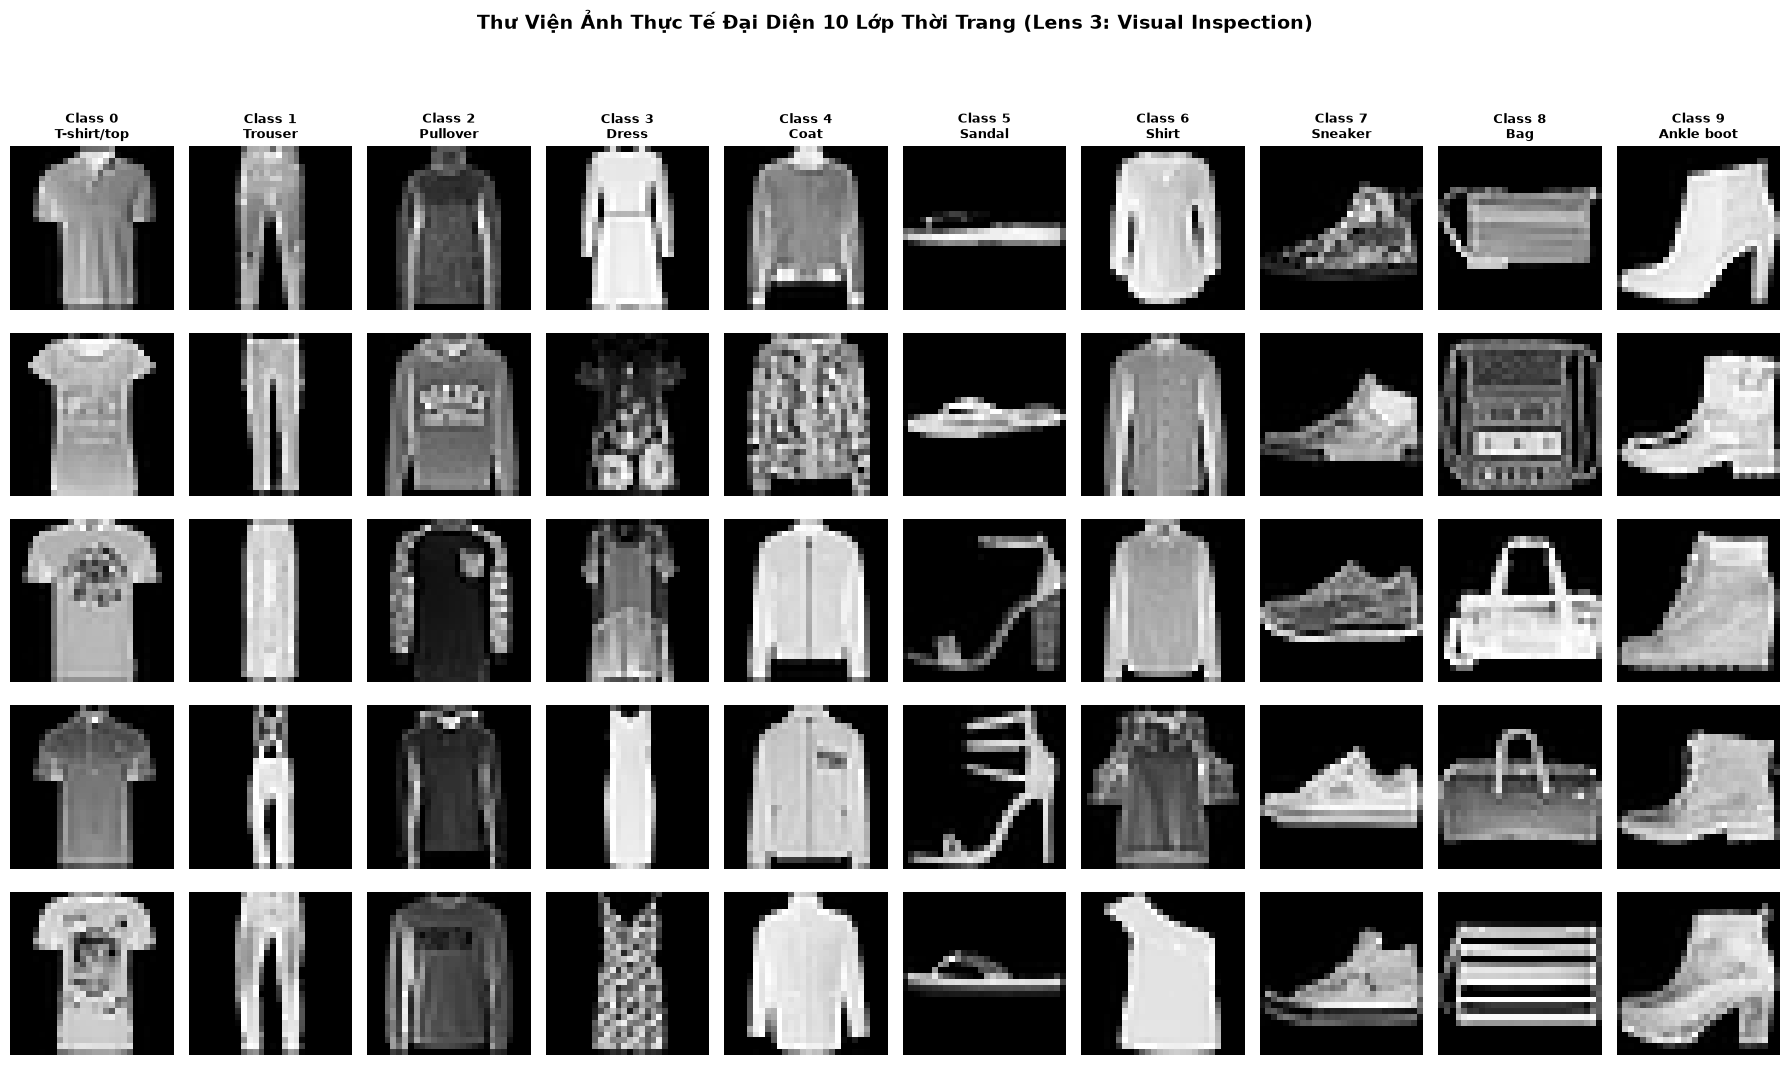

In [8]:
fig_gallery = eda_helpers.plot_gallery(train_imgs, train_tgts, samples_per_class=5)
plt.show()

- Ảnh đồng nhất $28 \times 28$, nền đen sạch và đối tượng căn giữa khung hình. Nhìn trực quan, lớp `Shirt` rất đa dạng — vừa có mẫu dài tay gần giống `Coat`/`Pullover`, vừa có mẫu dáng ngắn giống `T-shirt/top` — tạo cơ sở trực quan cho giả thuyết lỗi tập trung ở nhóm áo (**H3**).

**2. Ảnh trung bình từng lớp (Class Prototypes)**

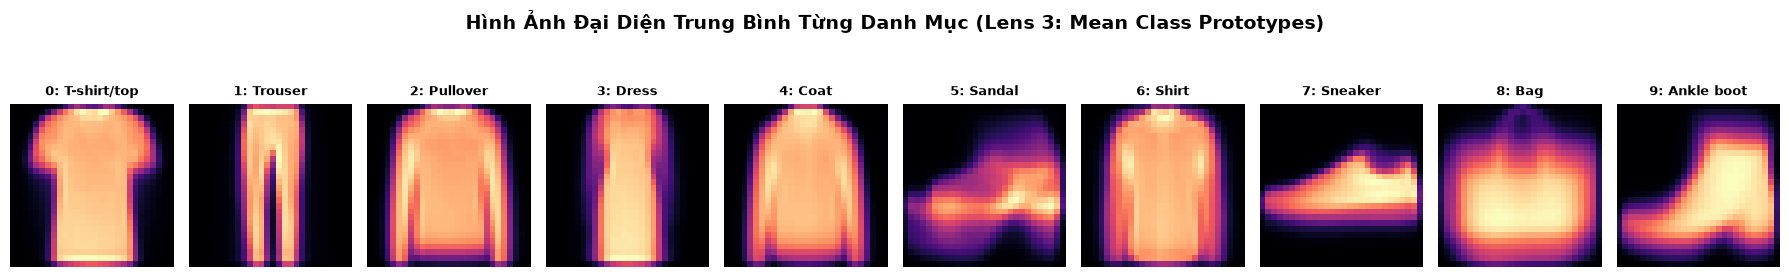

In [9]:
class_prototypes = eda_helpers.compute_class_prototypes(train_imgs, train_tgts)
fig_prototypes = eda_helpers.plot_prototypes_gallery(class_prototypes)
plt.show()

- Ảnh trung bình pixel của `Pullover`, `Coat`, `Shirt` có hình bóng (silhouette) gần như trùng khít nhau, còn `T-shirt/top` chung phần thân và chỉ khác chủ yếu ở độ dài tay; ngược lại `Trouser`, `Bag` và nhóm giày dép có hình thái trung bình khác biệt rõ.

**3. Ma trận Cosine Similarity (giữa các Class Prototype) & PCA 2D**

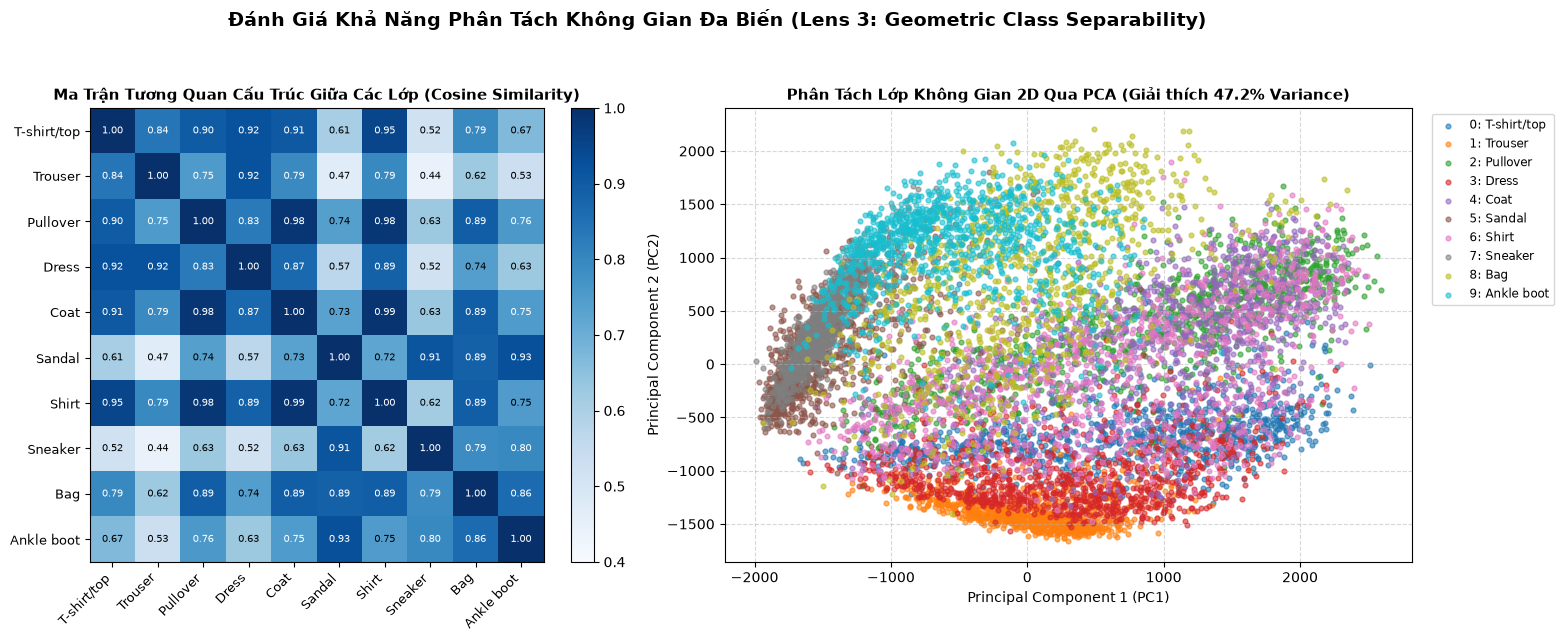

In [10]:
sample_size = 10000
sample_images  = train_imgs[:sample_size]
sample_targets = train_tgts[:sample_size]

fig_sim_pca = eda_helpers.plot_interclass_similarity_and_pca(class_prototypes, sample_images, sample_targets)
plt.show()

- **Cosine similarity đo giữa 10 vector class prototype (ảnh trung bình 784 chiều của từng lớp)**: toàn bộ các cặp trong nhóm áo thân trên (`T-shirt/top`, `Pullover`, `Coat`, `Shirt`) đều đạt **0.90–0.99** (`Coat ↔ Shirt: 0.99`, `Pullover ↔ Coat: 0.98`, `Pullover ↔ Shirt: 0.98`, `T-shirt/top ↔ Shirt: 0.95`, `T-shirt/top ↔ Coat: 0.91`, `T-shirt/top ↔ Pullover: 0.90`).
- **PCA 2D (10.000 mẫu Train, `seed = 248`)**: hai thành phần đầu chỉ giải thích **47.19%** tổng phương sai (`PC1 = 29.65%`, `PC2 = 17.54%`). Trên mặt phẳng chiếu này, nhóm giày dép gom về phía trái (`PC1 < -1000`), `Trouser` gom ở cạnh dưới (`PC2 < -1200`), còn 4 lớp áo thân trên trộn lẫn dày đặc ở phía phải (`PC1 > 0`). **Lưu ý**: vì PCA 2D bỏ qua hơn 52% phương sai còn lại, việc tách cụm hay chồng lấn trên đồ thị 2D chỉ là bằng chứng gián tiếp ở phép chiếu tuyến tính thấp chiều, không đủ kết luận ranh giới thực trong không gian 784 chiều.

#### Quyết định cho bước tiếp theo
1. Chuẩn hóa Z-Score với `mean`, `std` tính duy nhất trên 55.000 mẫu Train.
2. Thử nghiệm Augmentation bảo toàn hướng đứng thời trang (lật ngang, dịch/xoay nhỏ) chỉ trên Train.
3. Cơ sở EDA cho **Hypotheses**: cosine similarity giữa các class prototype của nhóm áo thân trên đạt **0.90–0.99** (kèm chồng lấn trên PCA 2D) là căn cứ đặt giả thuyết lỗi sẽ tập trung ở nhóm này (**H3**) và cấu trúc lưới 2D của `CNN` sẽ tách tốt hơn `MLP` flatten (**H1**). (Riêng **H2** về augmentation xuất phát từ thiết kế thí nghiệm, không phải từ EDA.)

---
## 4. Data Processing

Pipeline xử lý đặt tại [`src/vibe_scripts/lab1/data.py`](../../../src/vibe_scripts/lab1/data.py) *(đặc tả chi tiết kỹ thuật xem tại [`docs/pipelines/01_DATA_PREPARATION.md`](docs/pipelines/01_DATA_PREPARATION.md))*:

- **Scaling**: đúng thứ tự `Augmentation → ToTensor → Normalize`; `mean` (`0.2862`) và `std` (`0.3531`) tính **duy nhất trên 55.000 mẫu Train**, áp dụng cố định cho Train, Validation và Test.
- **Augmentation**: nhánh `no_aug` chỉ `ToTensor → Normalize`; nhánh `aug` **chỉ áp dụng trên Train** (`RandomHorizontalFlip(p=0.5)` + `RandomAffine(degrees=10, translate=(0.08, 0.08))`), tách độc lập đối tượng dữ liệu Train và Validation chống rò rỉ. Không dùng lật dọc vì ảnh quần áo/giày dép có hướng trọng lực cố định.
- **DataLoader**: `batch_size = 32`, `shuffle = True` (chỉ Train), `pin_memory = True` (GPU), `seed = 248`.

In [11]:
from labs.lab1.vibe import config as lab1_cfg
from src.vibe_scripts.lab1 import data as lab1_data
from src.vibe_scripts.lab1 import models as lab1_models
from src.vibe_scripts.lab1 import train as lab1_train
from src.vibe_scripts.lab1 import evaluate as lab1_eval
from src.vibe_scripts.lab1 import infer as lab1_infer

# Dùng num_workers=0 trong notebook để tránh overhead spawn multiprocessing trên Windows
train_loader_no_aug, val_loader, test_loader, norm_stats = lab1_data.build_dataloaders(
    aug_enabled=False, num_workers=0
)
train_loader_aug, _, _, _ = lab1_data.build_dataloaders(
    aug_enabled=True, num_workers=0, verify_manifest=False
)

df_proc = pd.DataFrame(
    [
        ("Mean chuẩn hóa (fit trên Train 55k)", f"{norm_stats['mean']:.6f}"),
        ("Std chuẩn hóa (fit trên Train 55k)",  f"{norm_stats['std']:.6f}"),
        ("Batch Size", str(lab1_cfg.BATCH_SIZE)),
        ("Learning Rate (Adam override)", str(lab1_cfg.LR)),
        ("Epochs", str(lab1_cfg.EPOCH)),
        ("Best Checkpoint Metric", str(lab1_cfg.BEST_METRIC)),
        ("Augmentation (chỉ Train aug)", f"HFlip(p={lab1_cfg.AUG_CONFIG['horizontal_flip_p']}), Affine(deg={lab1_cfg.AUG_CONFIG['rotation_degrees']}, trans={lab1_cfg.AUG_CONFIG['translate']})"),
    ],
    columns=["Cấu hình", "Giá trị"],
)
v_objConsole.print(consoles.df_to_table(df_proc, title="PIPELINE 01: DATA PROCESSING & CONFIG OVERRIDE"))

                       PIPELINE 01: DATA PROCESSING & CONFIG OVERRIDE                       
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Cấu hình                            ┃ Giá trị                                            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Mean chuẩn hóa (fit trên Train 55k) │ 0.286169                                           │
│ Std chuẩn hóa (fit trên Train 55k)  │ 0.353101                                           │
│ Batch Size                          │ 32                                                 │
│ Learning Rate (Adam override)       │ 0.001                                              │
│ Epochs                              │ 20                                                 │
│ Best Checkpoint Metric              │ val_loss                                           │
│ Augmentation (chỉ Train aug)        │ HFlip(p=0.5), Affine(deg=10.0, trans=(0.08, 0.08)) │
└─────────────────────────────────────┴────────────────────────────────────────────────────┘
                                      7 rows × 2 cols                                       

---
## 5. Model Selection

- **`Logistic`**: Mô hình tuyến tính đơn giản nhất, làm mốc sàn (baseline) để đo mức cải thiện của mạng sâu (`7.850` tham số).
- **`MLP`**: Bổ sung 2 tầng ẩn phi tuyến ReLU để vượt giới hạn siêu phẳng tuyến tính của `Logistic`; vẫn làm phẳng ảnh thành vector 784 chiều nên đánh mất tương quan không gian 2D (`109.386` tham số).
- **`CNN`**: Giữ nguyên cấu trúc lưới 2D qua tích chập $3 \times 3$ và `MaxPool2d`, số tham số cùng bậc `MLP` (`105.866` tham số, chênh ~3,2%).

```text
Logistic:  [B,1,28,28] → Flatten [B,784] → Linear(784→10) [B,10]
MLP:       [B,1,28,28] → Flatten [B,784] → Linear(784→128) → ReLU → Linear(128→64) → ReLU → Linear(64→10) [B,10]
CNN:       [B,1,28,28] → Conv(1→16, 3×3) → ReLU → Pool2 → Conv(16→32, 3×3) → ReLU → Pool2 → Flatten [B,1568] → Linear(1568→64) → ReLU → Linear(64→10) [B,10]
```

*(Chi tiết hợp đồng I/O và kiểm chứng toán học số tham số xem tại [`docs/pipelines/02_MODEL_ARCHITECTURE.md`](docs/pipelines/02_MODEL_ARCHITECTURE.md).)*

In [12]:
dummy_x = torch.randn(4, 1, 28, 28)
model_rows = []
for m_name in lab1_cfg.MODEL_NAMES:
    m = lab1_models.build_model(m_name)
    out = m(dummy_x)
    model_rows.append((m_name.upper(), f"{lab1_models.count_parameters(m):,}", str(tuple(out.shape))))

df_models = pd.DataFrame(model_rows, columns=["Mô hình", "Số tham số", "Output Shape (Dummy B=4)"])
v_objConsole.print(consoles.df_to_table(df_models, title="PIPELINE 02: MODEL ARCHITECTURES SUMMARY"))

      PIPELINE 02: MODEL ARCHITECTURES SUMMARY      
┏━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Mô hình  ┃ Số tham số ┃ Output Shape (Dummy B=4) ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ LOGISTIC │ 7,850      │ (4, 10)                  │
│ MLP      │ 109,386    │ (4, 10)                  │
│ CNN      │ 105,866    │ (4, 10)                  │
└──────────┴────────────┴──────────────────────────┘
                  3 rows × 3 cols                   

---
## 6. Baseline & Training

Pipeline huấn luyện đặt tại [`src/vibe_scripts/lab1/train.py`](../../../src/vibe_scripts/lab1/train.py) *(đặc tả kỹ thuật tại [`docs/pipelines/03_TRAINING.md`](docs/pipelines/03_TRAINING.md))*:
- **Loss & Optimizer**: `CrossEntropyLoss` (raw logits `[B, 10]`) + `Adam(lr=1e-3)` (override từ `1e-5` tại [`config.py`](config.py)).
- **Cấu hình**: `batch_size = 32`, `epochs = 20`, `seed = 248`, lưu nguyên tử `best.pt` (theo `val_loss` thấp nhất), `last.pt` và `history.json`.

### 6.1 Baseline Sanity Check (`Logistic`)
Tạo mốc sàn (`0`) và xác thực đường truyền gradient trước khi chạy full 6 thí nghiệm:
- Initial loss khởi tạo trước huấn luyện $\approx \ln(10) \approx 2.3026$.
- Khả năng overfit 1 batch (32 mẫu): accuracy > 95%.

In [13]:
sanity = lab1_train.run_sanity_check("logistic", train_loader_no_aug, device=lab1_cfg.DEVICE, lr=0.05, steps=80)
df_sanity = pd.DataFrame(
    [
        ("Initial Loss (kỳ vọng ~2.3026)", f"{sanity['initial_loss']:.4f}"),
        ("Overfit 1 Batch Final Loss", f"{sanity['overfit_final_loss']:.4f}"),
        ("Overfit 1 Batch Final Accuracy", f"{sanity['overfit_final_acc']*100:.2f}%"),
    ],
    columns=["Kiểm tra Sanity (Logistic)", "Kết quả"],
)
v_objConsole.print(consoles.df_to_table(df_sanity, title="BASELINE SANITY CHECK"))

           BASELINE SANITY CHECK            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ Kiểm tra Sanity (Logistic)     ┃ Kết quả ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ Initial Loss (kỳ vọng ~2.3026) │ 2.4140  │
│ Overfit 1 Batch Final Loss     │ 0.0000  │
│ Overfit 1 Batch Final Accuracy │ 100.00% │
└────────────────────────────────┴─────────┘
              3 rows × 2 cols               

### 6.2 Huấn Luyện Ma Trận Thực Nghiệm 3 × 2

Chạy công bằng 6 cấu hình (`{logistic, mlp, cnn} × {no_aug, aug}`, `20 epochs`, `Adam lr=1e-3`, `seed=248`), tổng hợp kết quả tại **best epoch** (cùng checkpoint với bước đánh giá Test).

In [ ]:
from tqdm.auto import tqdm

train_summaries = []
runs = [(m, a) for m in lab1_cfg.MODEL_NAMES for a in lab1_cfg.AUG_MODES]
for m_name, aug_flag in tqdm(runs, desc="All Experiments (3x2)"):
    tr_loader = train_loader_aug if aug_flag else train_loader_no_aug
    res = lab1_train.train_experiment(
        model_name=m_name,
        aug_enabled=aug_flag,
        epochs=lab1_cfg.EPOCH,
        lr=lab1_cfg.LR,
        seed=lab1_cfg.SEED,
        best_metric=lab1_cfg.BEST_METRIC,
        train_loader=tr_loader,
        val_loader=val_loader,
        norm_stats=norm_stats,
        show_progress=True,
    )
    best_ep = res["history"][res["best_epoch"] - 1]
    gap_loss = best_ep["val_loss"] - best_ep["train_loss"]
    train_summaries.append((
        res["exp_id"],
        res["best_epoch"],
        f"{best_ep['train_loss']:.4f}",
        f"{best_ep['val_loss']:.4f}",
        f"{gap_loss:+.4f}",
        f"{best_ep['train_acc']*100:.2f}%",
        f"{best_ep['val_acc']*100:.2f}%",
        f"{res['total_train_time_sec']:.1f}s",
    ))

df_train = pd.DataFrame(
    train_summaries,
    columns=["Exp ID", "Best Epoch", "Train Loss @best", "Val Loss @best", "Gap Loss @best", "Train Acc @best", "Val Acc @best", "Total Time"],
)
v_objConsole.print(consoles.df_to_table(df_train, title="PIPELINE 03: TRAINING SUMMARY @ BEST EPOCH (6 CONFIGURATIONS)"))

---
## 7. Evaluate

Thực thi bằng [`src/vibe_scripts/lab1/evaluate.py`](../../../src/vibe_scripts/lab1/evaluate.py) *(đặc tả kỹ thuật tại [`docs/pipelines/04_EVALUATION_BENCHMARK.md`](docs/pipelines/04_EVALUATION_BENCHMARK.md))*.

### 7.1 Nguyên tắc & Metric tổng hợp (3 mô hình × 2 cấu hình)
- Tập Test `10.000` mẫu chỉ được đánh giá **đúng 1 lần** trên `best.pt` (chọn theo `val_loss` thấp nhất) để tránh rò rỉ thông tin từ Test.
- Toàn bộ suy luận dưới `model.eval()` + `torch.no_grad()`, warm-up 2 batch trước khi bấm giờ.
- Kiểm chứng Save/Load: sai số tối đa `|logits_before − logits_after| < 1e-6`.

In [14]:
benchmark_out = lab1_eval.run_benchmark(
    experiments_dir=lab1_cfg.EXPERIMENT_DIR,
    test_loader=test_loader,
    device=lab1_cfg.DEVICE,
)

df_bench = pd.DataFrame(benchmark_out["benchmark_rows"])
v_objConsole.print(consoles.df_to_table(df_bench, title="PIPELINE 04: METRIC TỔNG HỢP (3 MODELS × 2 CONFIGS)"))

max_save_load_diff = max(
    details["save_load_max_diff"] for details in benchmark_out["experiments"].values()
)
print(f"Kiểm chứng Save/Load (max |logits_before - logits_after| trên cả 6 cấu hình): {max_save_load_diff:.2e} (< 1e-6)")

                                PIPELINE 04: METRIC TỔNG HỢP (3 MODELS × 2 CONFIGS)                                
┏━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┓
┃ exp_id   ┃ model    ┃ aug    ┃ params ┃ best_ep… ┃ file_si… ┃ test_l… ┃ test_ac… ┃ macro_… ┃ latency… ┃ save_l… ┃
┡━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━┩
│ cnn_aug  │ cnn      │ aug    │ 105866 │       16 │ 1250.820 │   0.265 │   90.740 │  90.720 │    1.882 │   0.000 │
│ cnn_no_… │ cnn      │ no_aug │ 105866 │        8 │ 1250.820 │   0.256 │   91.130 │  91.040 │    1.674 │   0.000 │
│ logisti… │ logistic │ aug    │   7850 │       17 │   95.890 │   0.721 │   74.680 │  74.770 │    1.177 │   0.000 │
│ logisti… │ logistic │ no_aug │   7850 │        4 │   95.890 │   0.463 │   83.820 │  83.470 │    1.173 │   0.000 │
│ mlp_aug  │ mlp      │ aug    │ 109386 │       16 │ 1289.590 │   0.399 │   85.620 │  85.530 │    1.340 │   0.000 │
│ mlp_no_… │ mlp      │ no_aug │ 109386 │        7 │ 1289.590 │   0.338 │   88.300 │  88.250 │    1.256 │   0.000 │
└──────────┴──────────┴────────┴────────┴──────────┴──────────┴─────────┴──────────┴─────────┴──────────┴─────────┘
                                                 6 rows × 11 cols                                                  

Kiểm chứng Save/Load (max |logits_before - logits_after| trên cả 6 cấu hình): 0.00e+00 (< 1e-6)


- **Kiểm chứng Save/Load**: Sai số tối đa `|logits_before - logits_after|` = **`0.0`** cho cả 6 cấu hình ✅ (yêu cầu `< 1e-6`).
- **Nhận xét metric tổng hợp**:
  - **Xếp hạng kiến trúc (`no_aug`, bằng chứng cho H1)**: Test Accuracy (`83.82 → 88.30 → 91.13%`), Macro F1 (`83.47 → 88.25 → 91.04%`) và Test Loss (`0.4628 → 0.3378 → 0.2558`) đều xếp hạng đồng nhất `CNN > MLP > Logistic`. Macro F1 sát Accuracy (lệch `< 0.5` điểm % ở mọi cấu hình) do tập Test cân bằng tuyệt đối 1.000 mẫu/lớp.
  - **Tác động của `aug` & mức độ chắc chắn (bằng chứng bác bỏ H2)**: Test Accuracy giảm lần lượt `−9.14 / −2.68 / −0.39` điểm % (`Logistic / MLP / CNN`) và Test Loss đều tăng (`+0.2584 / +0.0608 / +0.0095`); mức giảm co lại khi kiến trúc mạnh hơn *(quan sát đo được, nguyên nhân chưa kiểm chứng)*. Riêng ở `CNN`, chênh lệch `0.39` điểm % accuracy (và `+0.0095` test loss) trên 10.000 mẫu với 1 seed có thể nằm gần ngưỡng nhiễu ngẫu nhiên, nên kết luận "aug không cải thiện" yếu nhất ở `CNN` và rõ nhất ở `Logistic`. Tuy nhiên, tiêu chí **H2** (`≥ 2/3` kiến trúc có `test_loss(aug) < test_loss(no_aug)`) vẫn bị bác bỏ ngay cả khi bỏ qua `CNN`, vì cả `Logistic` lẫn `MLP` đều suy giảm rõ rệt.
  - **Chi phí so với lợi ích**: `CNN` (`105.866` tham số, `1250.82 KB`) nhỏ hơn `MLP` (`109.386` tham số, `1289.59 KB`) khoảng `3,2%` nhưng vượt `+2.83` điểm % accuracy; vượt `Logistic` `+7.31` điểm % với số tham số gấp `~13,5` lần (`95.89 KB → 1250.82 KB`, kích thước checkpoint tỷ lệ thuận với số tham số).
  - **Best epoch & Latency**: Nhánh `no_aug` đạt best epoch sớm (`4 / 7 / 8`), còn `aug` muộn hơn (`17 / 16 / 16`), nhất quán với việc augmentation làm bài toán huấn luyện khó hơn *(lưu ý về nhiễu val loss ở Logistic xem mục Learning Curves bên dưới)*. Cột `Infer Latency` chỉ mang tính tham khảo, không dùng để so sánh kiến trúc vì cùng kiến trúc `aug`/`no_aug` đã lệch **23.8–46.4%** so với `no_aug` (xem mục Hạn chế và kết luận #4).

### 7.2 Đường cong học (Learning Curves) — So sánh tổng thể

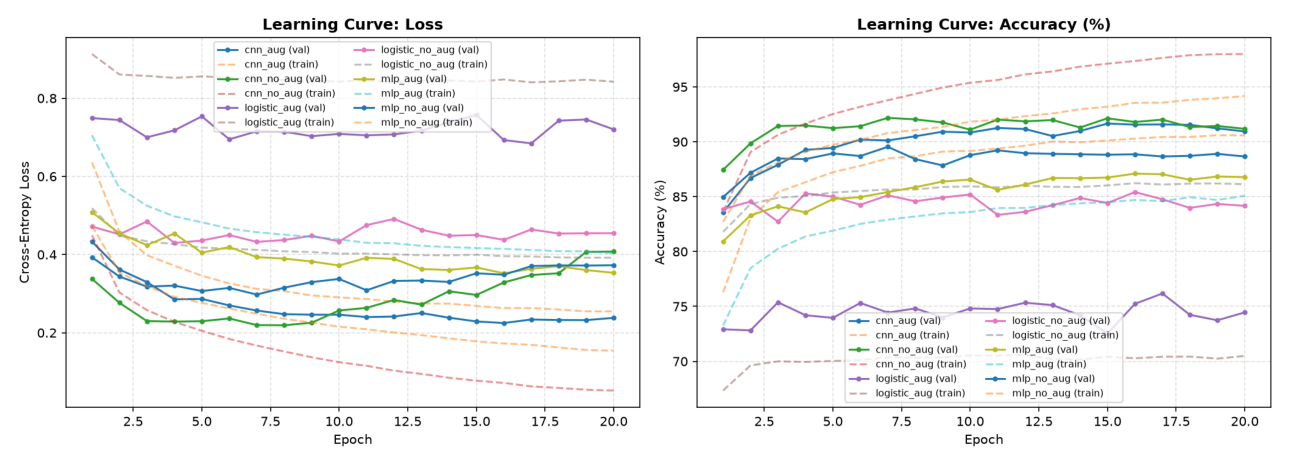

In [15]:
def show_saved_image(filename: str, figsize=(13, 5.5), title: str | None = None) -> None:
    p = lab1_cfg.PREDICTIONS_DIR / filename
    if not p.exists():
        print(f"[MISSING] {p}")
        return
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(Image.open(p))
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()


def show_image_pair(left_file: str, right_file: str, left_title: str, right_title: str, figsize=(16, 6.5)) -> None:
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, fname, title in zip(axes, [left_file, right_file], [left_title, right_title]):
        p = lab1_cfg.PREDICTIONS_DIR / fname
        if p.exists():
            ax.imshow(Image.open(p))
            ax.set_title(title, fontsize=11, fontweight="bold")
        else:
            ax.text(0.5, 0.5, f"Missing: {fname}", ha="center", va="center")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_saved_image("learning_curves_comparison.png", figsize=(13, 5.5))

- **Nhận xét**: Best epoch nhánh `no_aug`: `Logistic` 4, `MLP` 7, `CNN` 8. Với `Logistic`, val loss dao động ±0.03 quanh 0.43–0.49 trong khi train loss vẫn giảm đến epoch 20 (0.427 → 0.392), nên best epoch 4 chỉ là điểm thấp nhất của một đường nhiễu, không phản ánh tốc độ hội tụ. `CNN (no_aug)` overfit nếu train tiếp — val loss tăng ngược từ epoch 8. Nhánh `aug` cho val loss < train loss ở cả 3 kiến trúc — đây là **artifact** do train loss đo trên ảnh augmented (khó hơn) còn val đo trên ảnh sạch, không phải bằng chứng hết overfit. `Logistic aug` giảm mạnh accuracy (−9.14 điểm %) dù đã hội tụ (train loss phẳng ~0.84 từ epoch 2); nguyên nhân chưa kiểm chứng, có thể do mô hình tuyến tính không tận dụng được augmentation, hoặc do distribution shift (ví dụ flip ngang) giữa train augmented và test sạch.

### 7.3 Learning curve riêng từng thí nghiệm

Mỗi thí nghiệm có 1 biểu đồ riêng gồm 2 panel (Loss + Accuracy), đánh dấu:
- **Best Epoch** (đường dọc tím) — epoch có `val_loss` thấp nhất.
- **Overfit Gap** (vùng tô mờ đỏ) — khoảng cách `val_loss − train_loss`. Bảng tổng hợp ghi gap **tại best epoch** (cùng checkpoint với test metrics) thay vì epoch cuối.

> **Lưu ý đọc gap**: Với nhánh `aug`, train loss đo trên ảnh augmented (khó hơn) còn val đo trên ảnh sạch, nên gap âm là **artifact** của augmentation, không phải bằng chứng hết overfit hay underfit.

#### Logistic

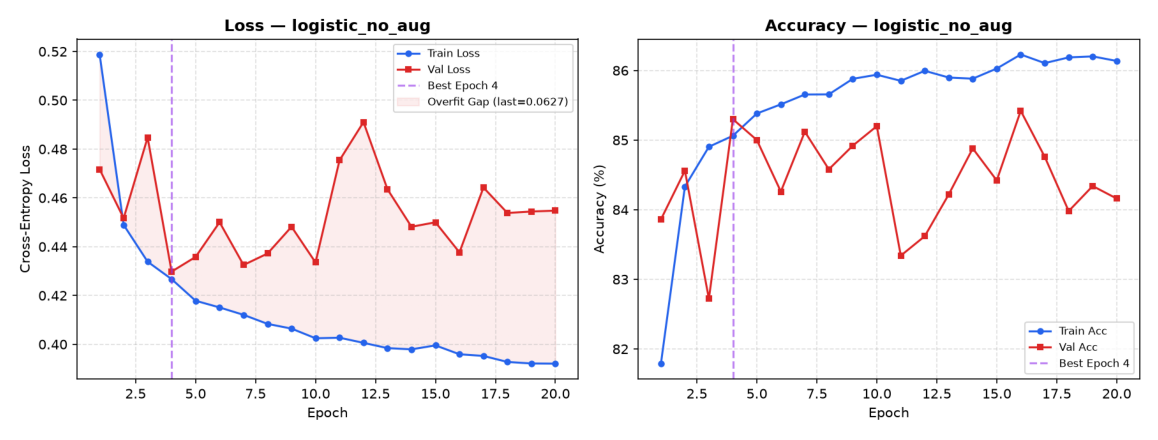

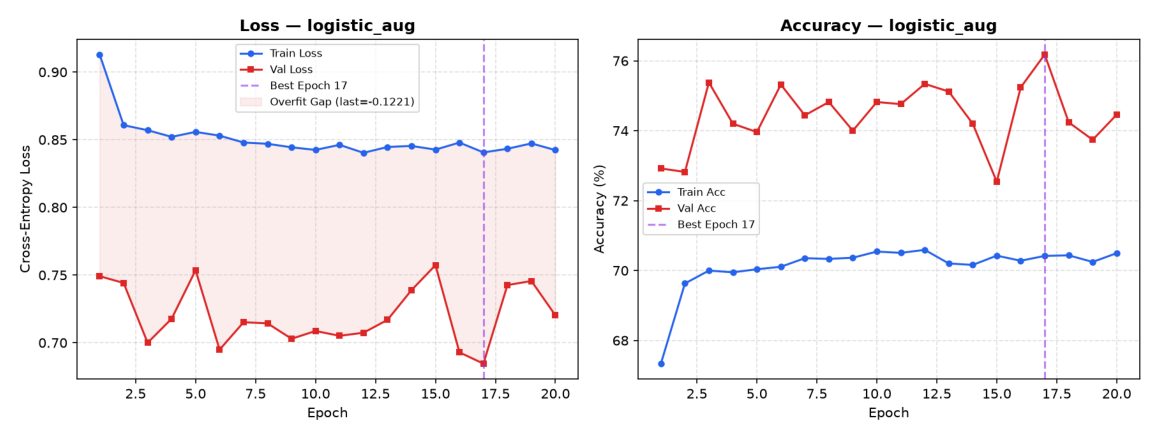

In [16]:
show_saved_image("learning_curve_logistic_no_aug.png", figsize=(12, 4.5))
show_saved_image("learning_curve_logistic_aug.png", figsize=(12, 4.5))

- **`no_aug`**: Best epoch 4: train_loss = 0.4267, val_loss = 0.4298, gap = +0.003 — gần như không overfit. Train loss vẫn giảm chậm đến epoch 20 (→ 0.392); val loss dao động ±0.03, nên best epoch 4 là điểm nhiễu thấp nhất chứ không phải dấu hiệu hội tụ sớm.
- **`aug`**: Train loss phẳng ~0.84 và train acc ~70% gần như không đổi từ epoch 2 → mô hình **đã hội tụ ở mức thấp**, không phải thiếu epoch. Best epoch 17 (val_loss = 0.6846) chỉ là điểm thấp nhất của val loss dao động mạnh (0.69–0.76). Test accuracy giảm 9.14 điểm % so với `no_aug`; nguyên nhân chưa kiểm chứng — có thể do mô hình tuyến tính không tận dụng được augmentation, hoặc do distribution shift (flip/affine) giữa train và test.

#### MLP

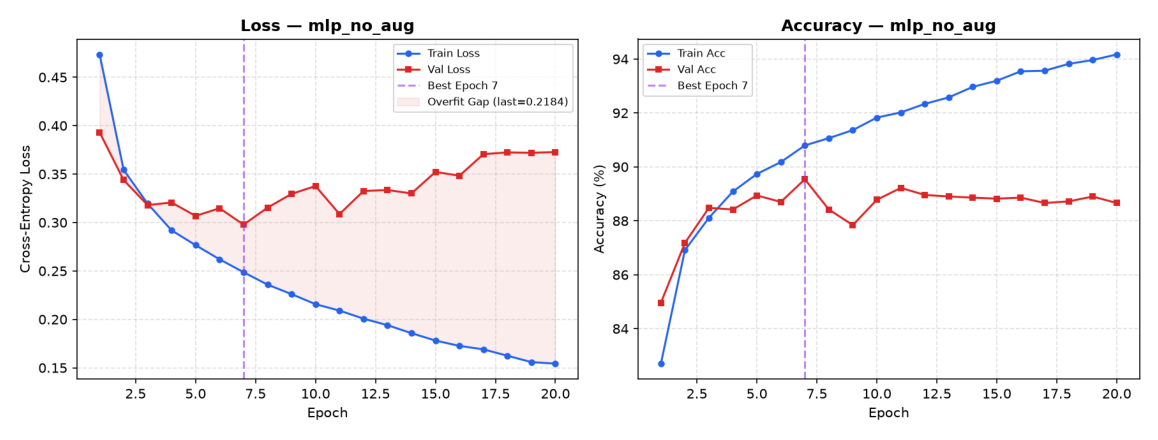

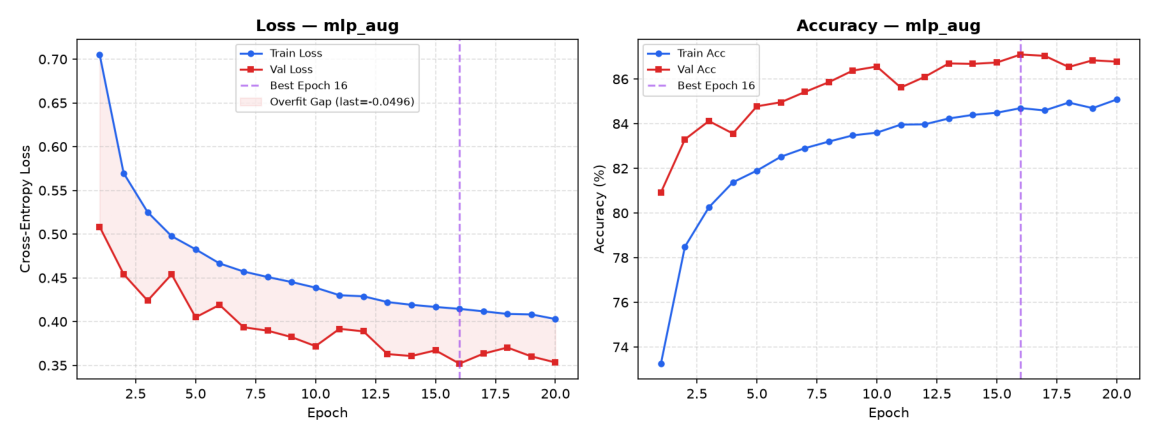

In [17]:
show_saved_image("learning_curve_mlp_no_aug.png", figsize=(12, 4.5))
show_saved_image("learning_curve_mlp_aug.png", figsize=(12, 4.5))

- **`no_aug`**: Tại best epoch 7: train_loss = 0.2487, val_loss = 0.2978, gap = +0.049 — overfit nhẹ. Từ epoch 7 trở đi val loss tăng ngược trong khi train loss tiếp tục giảm → overfit ngày càng nặng.
- **`aug`**: Tại best epoch 16: train_loss = 0.4146, val_loss = 0.3520, gap = −0.063 (artifact). Test accuracy giảm 2.68 điểm % so với `no_aug`. Train loss vẫn giảm chậm đến epoch 20, nên giả thuyết "chưa đủ epoch" còn hợp lý; ngoài ra có thể do MLP flatten ảnh nên biến đổi spatial không giúp nhiều.

#### CNN

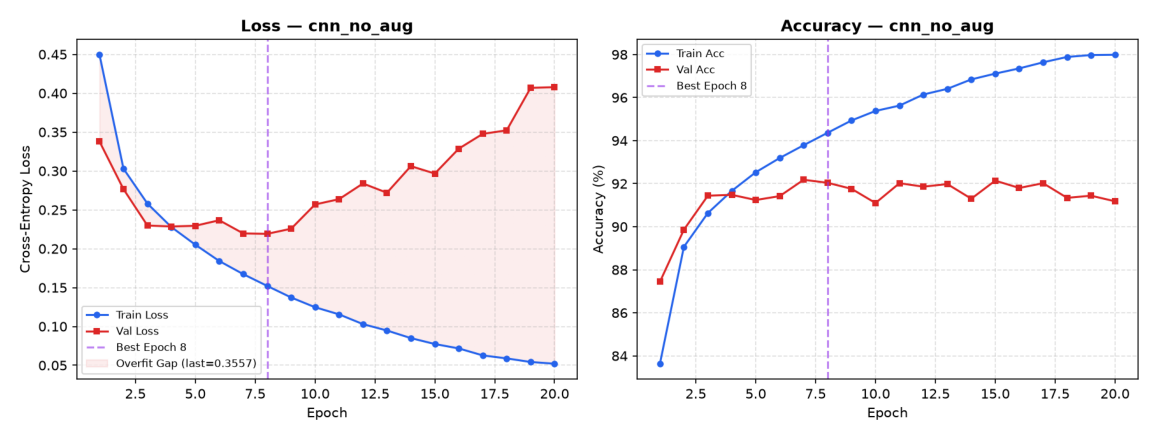

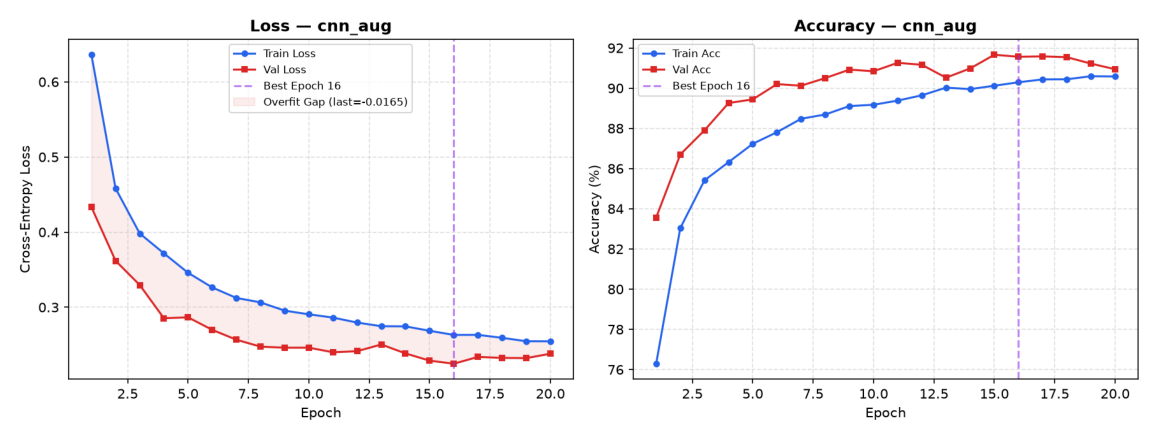

In [18]:
show_saved_image("learning_curve_cnn_no_aug.png", figsize=(12, 4.5))
show_saved_image("learning_curve_cnn_aug.png", figsize=(12, 4.5))

- **`no_aug`**: Tại best epoch 8: train_loss = 0.1521, val_loss = 0.2191, gap = +0.067. Overfit vừa phải tại thời điểm best, nhưng từ epoch 8 trở đi val loss tăng liên tục (0.408 ở epoch 20) → model ghi nhớ dữ liệu train nếu train tiếp.
- **`aug`**: Tại best epoch 16: train_loss = 0.2632, val_loss = 0.2248, gap = −0.038 (artifact). Train và val loss đều giảm song song đến epoch 16, không có val loss tăng ngược; train loss vẫn giảm chậm đến epoch 20 nên giả thuyết "chưa đủ epoch" còn hợp lý. Mất 0.39 điểm % accuracy (91.13 → 90.74).

| Thí nghiệm | Best Epoch | Train Loss (@best) | Val Loss (@best) | Gap Loss (@best) | Nhận xét |
| :--- | :---: | :---: | :---: | :---: | :--- |
| `logistic_no_aug` | `4` | `0.4267` | `0.4298` | `+0.003` | Gần như không overfit tại best epoch |
| `logistic_aug` | `17` | `0.8406` | `0.6846` | `−0.156` | Gap âm là artifact; train loss phẳng từ ep2, test acc −9.14 điểm % |
| `mlp_no_aug` | `7` | `0.2487` | `0.2978` | `+0.049` | Overfit nhẹ tại best; sau epoch 7 val loss tăng ngược |
| `mlp_aug` | `16` | `0.4146` | `0.3520` | `−0.063` | Gap âm là artifact; test acc −2.68 điểm % so với no_aug |
| `cnn_no_aug` | `8` | `0.1521` | `0.2191` | `+0.067` | Overfit vừa tại best; sau epoch 8 val loss tăng mạnh |
| `cnn_aug` | `16` | `0.2632` | `0.2248` | `−0.038` | Gap âm là artifact; val loss giảm đều, mất 0.39 điểm % acc |

### 7.4 Phân tích theo lớp (Per-class F1)

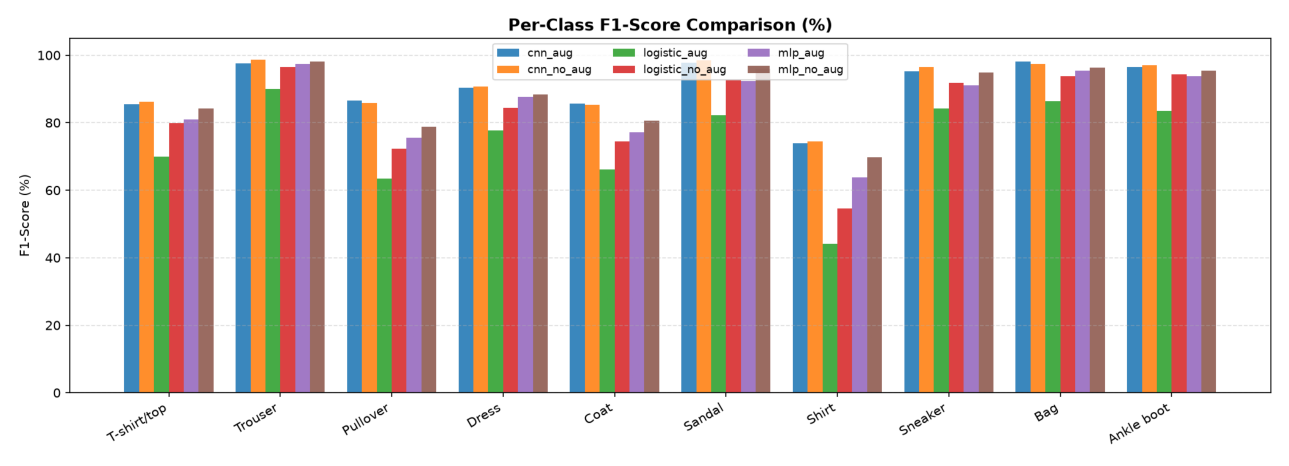

                             PER-CLASS F1 SCORE (%) ACROSS ALL 6 CONFIGS                             
┏━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ ID ┃ Label       ┃ Log (no_aug) ┃ MLP (no_aug) ┃ CNN (no_aug) ┃ Log (aug) ┃ MLP (aug) ┃ CNN (aug) ┃
┡━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━┩
│  0 │ T-shirt/top │ 79.91%       │ 84.14%       │ 86.12%       │ 69.98%    │ 80.93%    │ 85.40%    │
│  1 │ Trouser     │ 96.44%       │ 98.07%       │ 98.59%       │ 89.96%    │ 97.43%    │ 97.54%    │
│  2 │ Pullover    │ 72.28%       │ 78.71%       │ 85.91%       │ 63.47%    │ 75.62%    │ 86.59%    │
│  3 │ Dress       │ 84.43%       │ 88.37%       │ 90.63%       │ 77.73%    │ 87.73%    │ 90.32%    │
│  4 │ Coat        │ 74.51%       │ 80.66%       │ 85.29%       │ 66.12%    │ 77.15%    │ 85.70%    │
│  5 │ Sandal      │ 92.69%       │ 96.04%       │ 98.40%       │ 82.19%    │ 92.28%    │ 97.76%    │
│  6 │ Shirt       │ 54.56%       │ 69.85%       │ 74.50%       │ 44.08%    │ 63.78%    │ 74.00%    │
│  7 │ Sneaker     │ 91.87%       │ 94.85%       │ 96.46%       │ 84.30%    │ 91.15%    │ 95.31%    │
│  8 │ Bag         │ 93.76%       │ 96.32%       │ 97.38%       │ 86.33%    │ 95.47%    │ 98.14%    │
│  9 │ Ankle boot  │ 94.27%       │ 95.50%       │ 97.09%       │ 83.51%    │ 93.79%    │ 96.42%    │
└────┴─────────────┴──────────────┴──────────────┴──────────────┴───────────┴───────────┴───────────┘
                                          10 rows × 8 cols                                           

In [19]:
show_saved_image("per_class_f1_comparison.png", figsize=(13, 5.5))

per_cls_rows = []
for cls_id, label in enumerate(eda_helpers.FASHION_CLASSES):
    row = [cls_id, label]
    for eid in ["logistic_no_aug", "mlp_no_aug", "cnn_no_aug", "logistic_aug", "mlp_aug", "cnn_aug"]:
        f1_val = benchmark_out["experiments"][eid]["per_class"][cls_id]["f1"] * 100
        row.append(f"{f1_val:.2f}%")
    per_cls_rows.append(row)

df_per_cls = pd.DataFrame(
    per_cls_rows,
    columns=["ID", "Label", "Log (no_aug)", "MLP (no_aug)", "CNN (no_aug)", "Log (aug)", "MLP (aug)", "CNN (aug)"],
)
v_objConsole.print(consoles.df_to_table(df_per_cls, title="PER-CLASS F1 SCORE (%) ACROSS ALL 6 CONFIGS"))

- **Nhận xét theo lớp (nhánh `no_aug`)**:
  - Nhóm dễ phân biệt (`Trouser` `98.59%`, `Sandal` `98.40%`, `Bag` `97.38%`, `Ankle boot` `97.09%`, `Sneaker` `96.46%` ở CNN): hình dáng riêng biệt, cả 3 mô hình đều cao *(Ankle boot phân biệt tốt, có thể nhờ đặc trưng cổ cao)*.
  - Nhóm thân trên: `Pullover` (`CNN` vượt `MLP` `+7.2` điểm %), `Dress` (`CNN` vượt `MLP` `+2.3` điểm %, có thể nhờ nhận dạng viền váy qua 2D), `T-shirt/top` (`CNN` tốt nhất, có thể nhờ bắt biên cổ áo), `Coat` thường nhầm với `Pullover` và `Shirt`.
  - **`Shirt`** là lớp **khó nhất** ở mọi cấu hình (`Logistic` `54.56%`, `MLP` `69.85%`, `CNN` `74.50%` ở `no_aug`; sang `aug` còn `Logistic` `44.08%`, `MLP` `63.78%`, `CNN` `74.00%`).

### 7.5 Kiểm tra giả thuyết (`H1–H3`)

| Giả thuyết | Tiêu chí | Kết quả thực nghiệm | Kết luận |
| :--- | :--- | :--- | :---: |
| **H1** | Chênh acc > 0.5 điểm % giữa mỗi cặp liền kề | CNN 91.13% (+2.83 điểm % so với MLP) > MLP 88.30% (+4.48 điểm % so với Logistic) > Logistic 83.82%. Mọi chênh lệch >> 0.5 điểm % | ✅ Đúng |
| **H2** | `test_loss(aug) < test_loss(no_aug)` cho ≥ 2/3 kiến trúc | CNN: 0.2653 > 0.2558 ❌ · MLP: 0.3986 > 0.3378 ❌ · Logistic: 0.7212 > 0.4628 ❌ → 0/3 kiến trúc đạt tiêu chí | ❌ Bác bỏ |
| **H3** | ≥ 4/5 cặp nhầm thuộc nhóm áo | Shirt→T-shirt (152), Coat→Pullover (92), Shirt→Pullover (67), Coat→Shirt (51), T-shirt→Shirt (49) → **5/5** thuộc nhóm áo | ✅ Đúng |

**Phân tích H2 (bác bỏ)**: Cả 3 kiến trúc đều có `test_loss(aug) > test_loss(no_aug)` (0/3 đạt tiêu chí). Overfit gap âm ở nhánh aug là **artifact** — train loss đo trên ảnh augmented (khó hơn ảnh gốc) nên val < train là hiển nhiên, không phải bằng chứng hết overfit. Để đánh giá tác động augmentation đúng cách, cần so sánh **test metrics** trên cùng test set sạch: CNN mất 0.39 điểm % acc, MLP mất 2.68 điểm %, Logistic mất 9.14 điểm %. Kết luận: trong thiết lập 20 epoch, augmentation không cải thiện test performance cho bất kỳ kiến trúc nào.

---
## 8. Error Analysis

> Accuracy/Loss chỉ cho một con số trung bình. Error analysis là mở từng mẫu sai ra xem, để biết nên sửa cái gì. *(Tham chiếu [`docs/references/DL_PIPELINE.md`](../../../docs/references/DL_PIPELINE.md).)*

### 8.1 Bước 1: Chia lỗi theo class (Confusion Matrix + Kỳ vọng vs Thực tế)

| Nhóm | Classes | Recall kỳ vọng | Thực tế (`CNN no_aug`, Recall / F1) | Ghi chú |
| :--- | :--- | :---: | :--- | :--- |
| Dễ phân biệt | `Trouser`, `Sandal`, `Sneaker`, `Bag`, `Ankle boot` | ~96–98% | Recall `96.6–98.7%` (F1 `96.46–98.59%`) | Khớp kỳ vọng; hình dáng khác biệt rõ |
| Khó phân biệt | `Pullover`, `Coat` | ~80% | `Pullover` `89.0%` / `85.91%`; `Coat` `81.2%` / `85.29%` | Tương đồng cấu trúc tay áo; cao hơn kỳ vọng nhẹ |
| Rất khó | `Shirt`, `T-shirt/top` | ~60% | `Shirt` `69.4%` / `74.50%`; `T-shirt/top` `91.2%` / `86.12%` | Chỉ `Shirt` thấp rõ; `T-shirt` recall cao nhưng bị giảm precision do nhận nhầm từ `Shirt` |

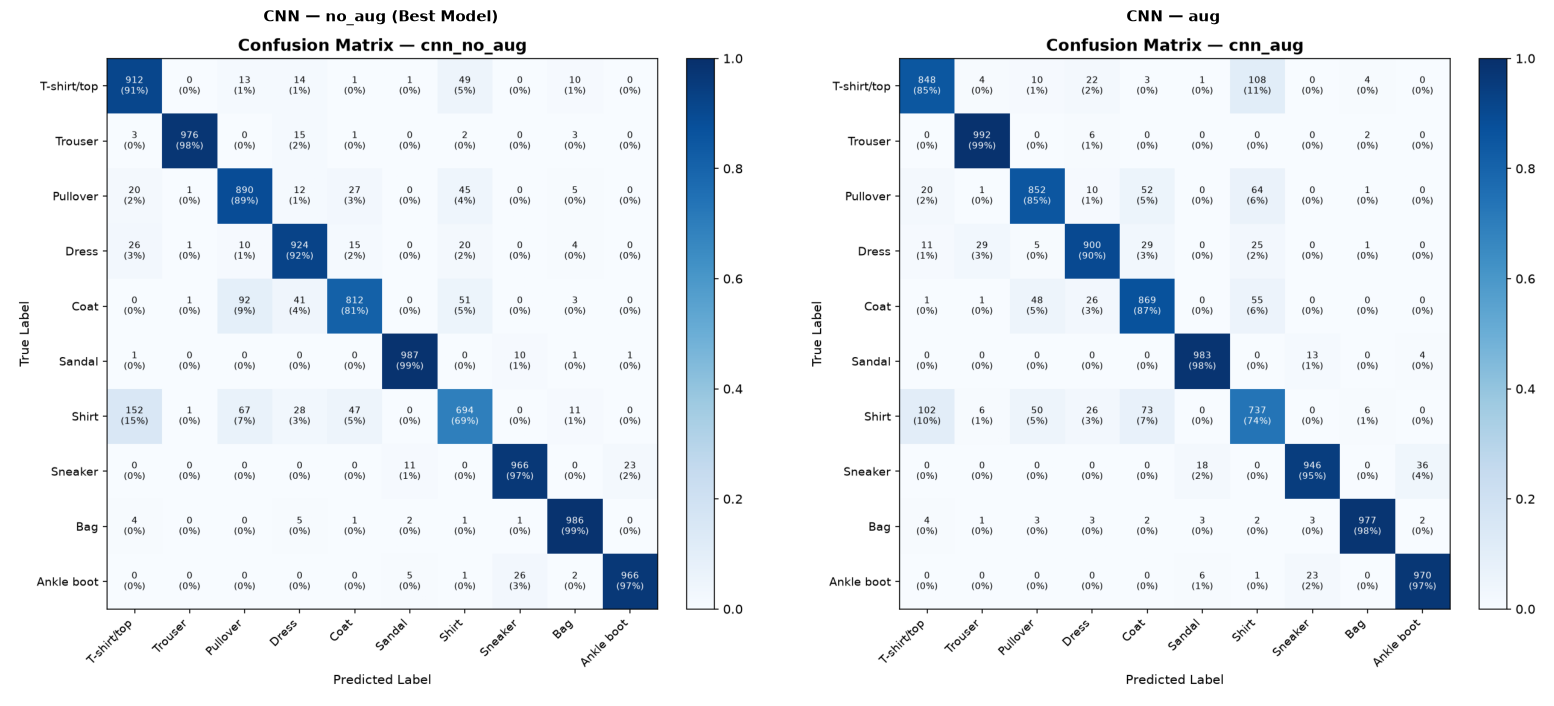

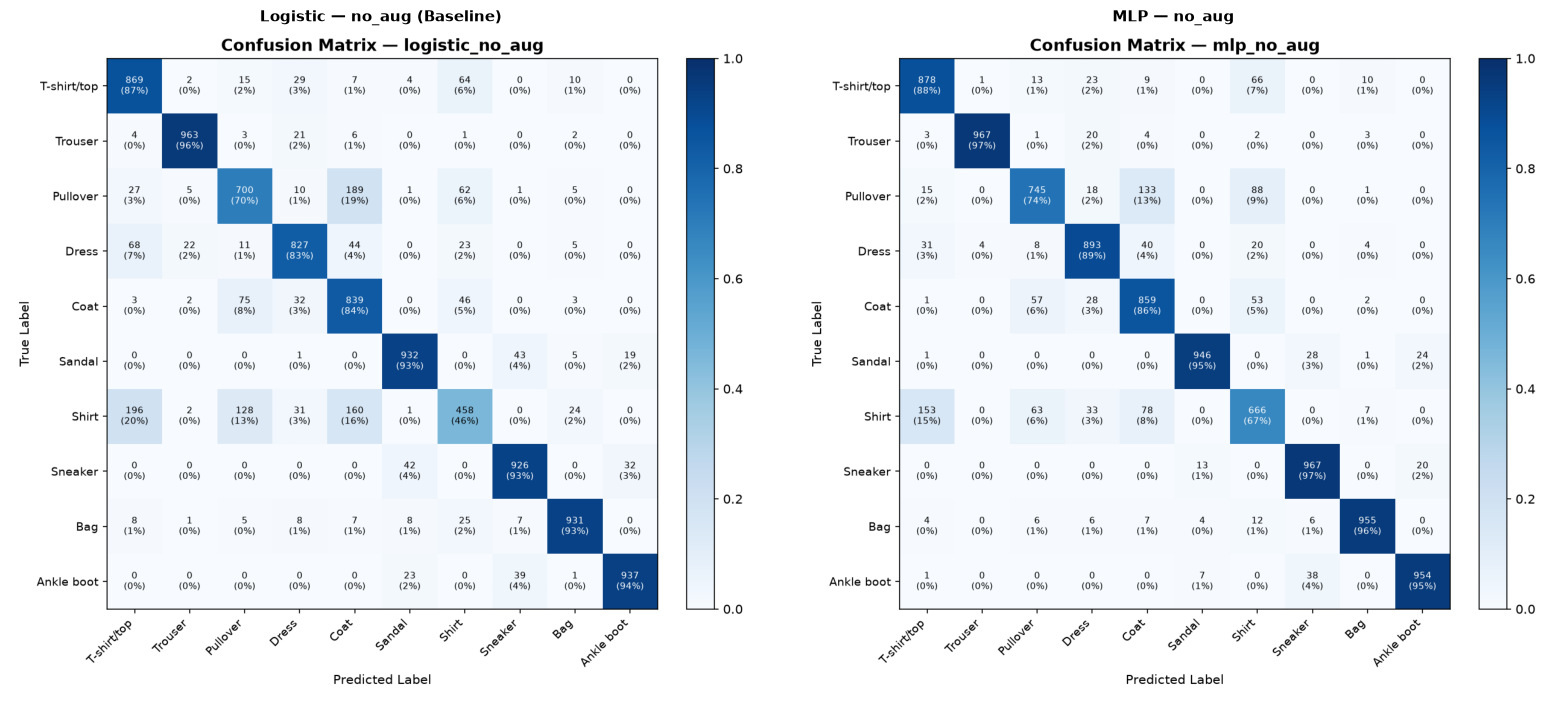

    TOP-5 CONFUSIONS — CNN_NO_AUG    
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━┓
┃ true_class  ┃ pred_class  ┃ count ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━┩
│ Shirt       │ T-shirt/top │   152 │
│ Coat        │ Pullover    │    92 │
│ Shirt       │ Pullover    │    67 │
│ Coat        │ Shirt       │    51 │
│ T-shirt/top │ Shirt       │    49 │
└─────────────┴─────────────┴───────┘
           5 rows × 3 cols           

     TOP-5 CONFUSIONS — CNN_AUG      
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━┓
┃ true_class  ┃ pred_class  ┃ count ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━┩
│ T-shirt/top │ Shirt       │   108 │
│ Shirt       │ T-shirt/top │   102 │
│ Shirt       │ Coat        │    73 │
│ Pullover    │ Shirt       │    64 │
│ Coat        │ Shirt       │    55 │
└─────────────┴─────────────┴───────┘
           5 rows × 3 cols           

In [20]:
show_image_pair(
    "confusion_matrix_cnn_no_aug.png",
    "confusion_matrix_cnn_aug.png",
    "CNN — no_aug (Best Model)",
    "CNN — aug",
    figsize=(16, 7),
)
show_image_pair(
    "confusion_matrix_logistic_no_aug.png",
    "confusion_matrix_mlp_no_aug.png",
    "Logistic — no_aug (Baseline)",
    "MLP — no_aug",
    figsize=(16, 7),
)

for eid in ["cnn_no_aug", "cnn_aug"]:
    df_conf = pd.DataFrame(benchmark_out["experiments"][eid]["top_confusions"])
    v_objConsole.print(consoles.df_to_table(df_conf, title=f"TOP-5 CONFUSIONS — {eid.upper()}"))

- **CNN (`no_aug` vs `aug`)**:
  - **`no_aug`**: Ô `Shirt → T-shirt/top` (152 mẫu) chiếm đậm nhất ngoài đường chéo. Khối 4×4 góc trên trái (`T-shirt`, `Pullover`, `Coat`, `Shirt`) có nhiều ô ngoài chéo đáng kể, trong khi nhóm giày/phụ kiện gần như trắng hoàn toàn.
  - **`aug`**: `Shirt → T-shirt` giảm từ 152 xuống 102 (khoảng −33%), nhưng chiều ngược lại `T-shirt → Shirt` tăng gấp đôi (49 → 108) và trở thành cặp nhầm lớn nhất. Augmentation **đổi kiểu lỗi** (dịch biên quyết định giữa hai lớp) chứ không chỉ giảm lỗi — phù hợp với việc Shirt recall tăng (69.4% → 73.7%) trong khi T-shirt recall giảm (91.2% → 84.8%).
- **Logistic vs MLP (`no_aug`)**:
  - **Logistic**: Confusion matrix "mờ" hơn — nhiều ô ngoài chéo có giá trị đáng kể, đặc biệt `Shirt` chỉ **458/1000** mẫu đúng (recall 45.8%, F1 54.6%). Mô hình tuyến tính không tách được biên quyết định phi tuyến giữa các lớp áo.
  - **MLP**: Cải thiện rõ so với Logistic (đường chéo đậm hơn), nhưng vẫn nhầm mạnh ở nhóm thân trên do flatten mất tương quan 2D.
- **Top-5 cặp nhầm lẫn (`CNN no_aug`)**: `Shirt → T-shirt/top` (152), `Coat → Pullover` (92), `Shirt → Pullover` (67), `Coat → Shirt` (51), `T-shirt/top → Shirt` (49) → **5/5** cặp nhầm lẫn lớn nhất đều thuộc nhóm thân trên — xác nhận giả thuyết **H3**.

### 8.2 Bước 2: Xem trực tiếp ảnh bị sai (Visual Inspection — Predictions Gallery)

Mỗi ảnh hiển thị 5 mẫu dự đoán đúng (viền xanh, hàng trên) + 5 mẫu dự đoán sai có độ tự tin Softmax cao nhất (viền đỏ, hàng dưới — *Top Confident Errors*).

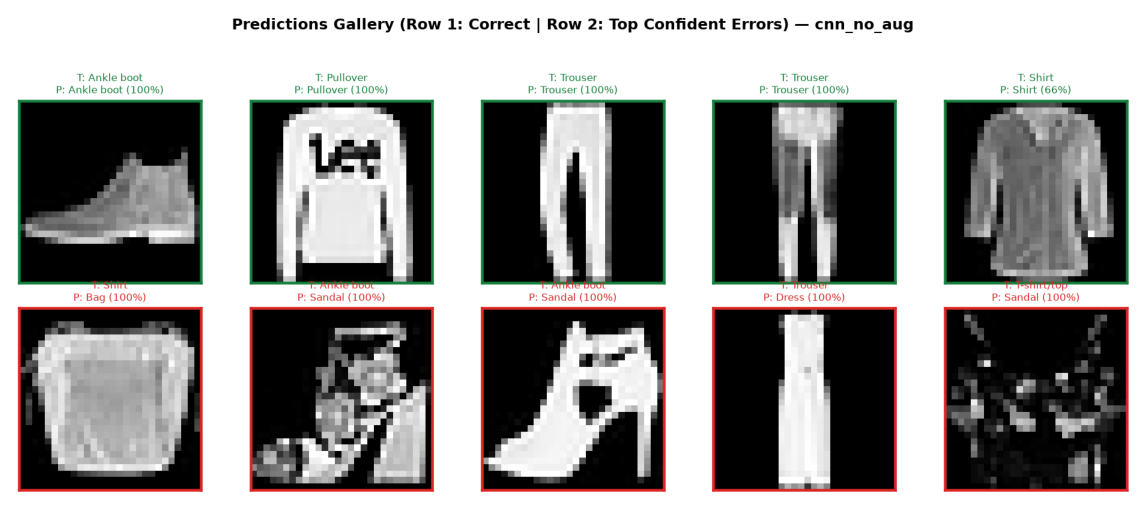

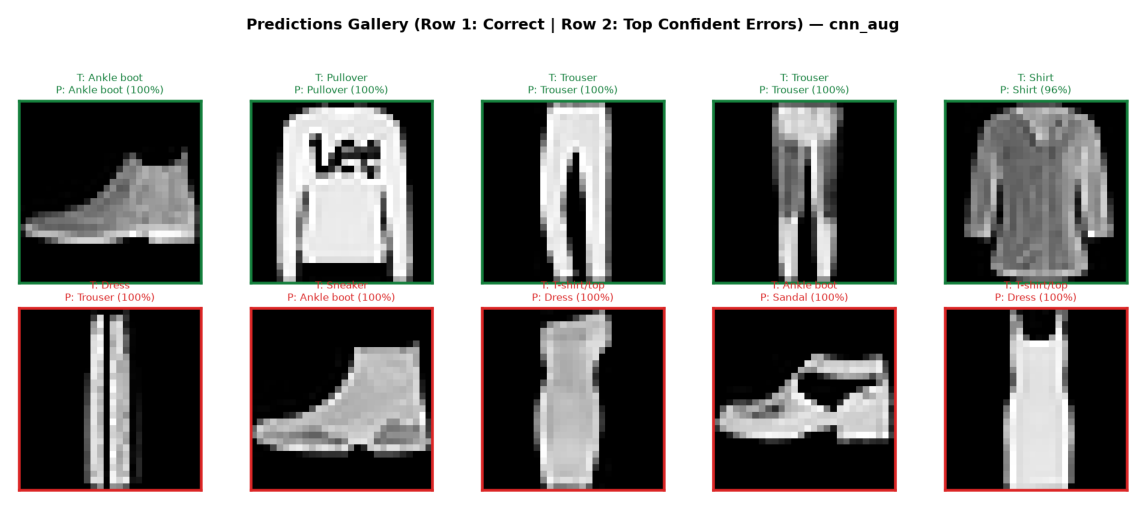

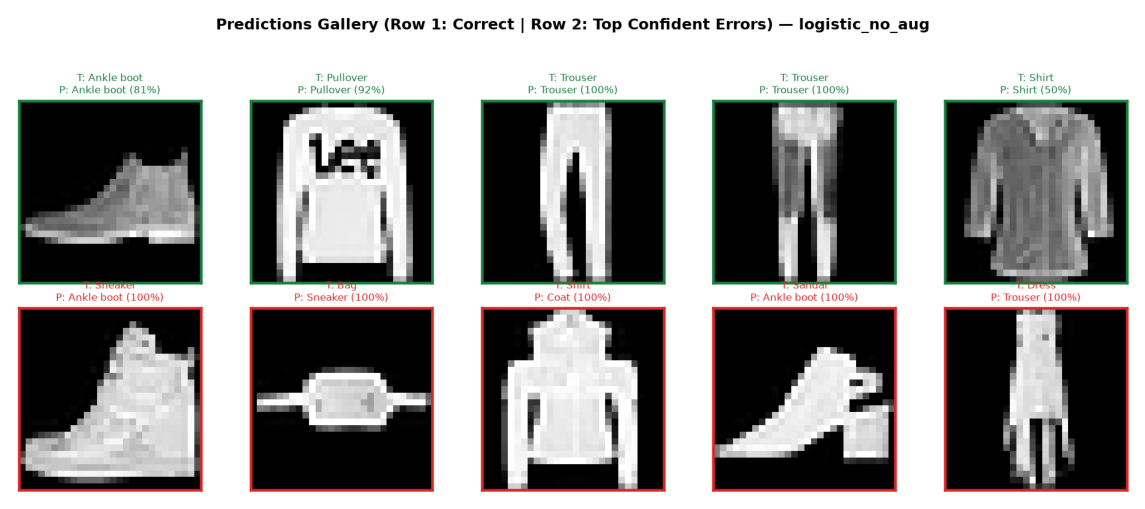

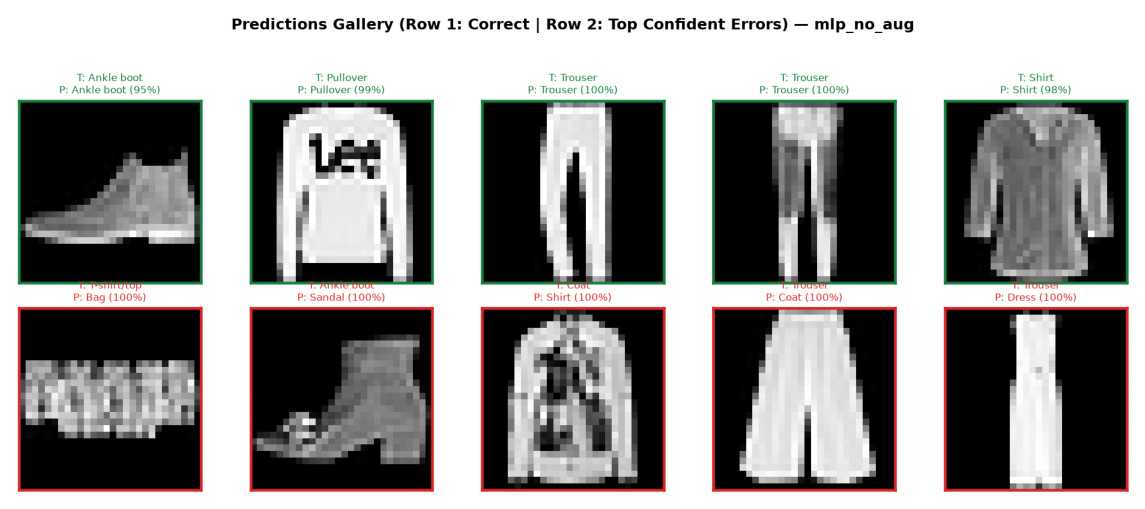

In [21]:
show_saved_image("predictions_gallery_cnn_no_aug.png", figsize=(13, 5.2))
show_saved_image("predictions_gallery_cnn_aug.png", figsize=(13, 5.2))
show_saved_image("predictions_gallery_logistic_no_aug.png", figsize=(13, 5.2))
show_saved_image("predictions_gallery_mlp_no_aug.png", figsize=(13, 5.2))

- **Quan sát — CNN (`no_aug` & `aug`, trong 5 mẫu sai hiển thị — Top Confident Errors)**:
  - Cả `CNN no_aug` và `CNN aug` đều đạt **softmax 100% ở cả 5/5 mẫu sai hiển thị** (phản ánh cả cách lọc *Top Confident Errors* lẫn hiện tượng overconfidence của softmax trên mẫu dị biệt).
  - **`CNN no_aug`**: 5 lỗi tự tin nhất là `Shirt → Bag`, `Ankle boot → Sandal` (2 mẫu), `Trouser → Dress`, `T-shirt/top → Sandal` — đều là ảnh hình dáng đặc biệt hoặc rất giống lớp bị dự đoán (áo gập khối vuông như túi, bốt hở hông/mũi như sandal, quần dính hai ống như váy, ảnh tối lốm đốm). Đáng chú ý, **không có mẫu `Shirt → T-shirt/top`** trong top 5 này.
  - **`CNN aug`**: 5 lỗi tự tin nhất là `Dress → Trouser`, `Sneaker → Ankle boot`, `T-shirt/top → Dress` (2 mẫu), `Ankle boot → Sandal` — tương tự, các mẫu rất mơ hồ về hình dạng (váy có sọc đen chia giữa trông như hai ống quần, giày cổ cao giống bốt, áo dáng dài giống váy).
- **Quan sát — Logistic vs MLP (`no_aug`, trong 5 mẫu sai hiển thị)**:
  - Cả `Logistic no_aug` và `MLP no_aug` cũng đạt **softmax 100% ở cả 5/5 mẫu sai hiển thị** (riêng ở 5 mẫu đúng hàng trên, `Logistic` có confidence thấp hơn rõ ở 3 mẫu: 81%, 92%, 50%, so với `MLP` 95–100%).
  - **`Logistic no_aug`**: `Sneaker → Ankle boot`, `Bag → Sneaker` (mẫu túi đeo ngang lạ), `Shirt → Coat`, `Sandal → Ankle boot`, `Dress → Trouser` — lỗi tự tin cao rải trên nhiều nhóm.
  - **`MLP no_aug`**: `T-shirt/top → Bag`, `Ankle boot → Sandal`, `Coat → Shirt`, `Trouser → Coat` (quần ống rộng), `Trouser → Dress` (trùng mẫu quần hẹp với `CNN no_aug`) — cũng tập trung vào các ảnh dị biệt ở nhiều lớp, không chỉ riêng nhóm áo.
- **Lưu ý phạm vi**: Gallery lọc 5 *Top Confident Errors* mỗi mô hình nên chủ yếu phơi bày các mẫu outlier/mơ hồ cực đoan, chưa đại diện cho lỗi phổ biến nhất (`Shirt ↔ T-shirt/top`). Cần lấy mẫu ngẫu nhiên 20–50 ảnh sai thuộc cặp `Shirt ↔ T-shirt/top` nếu muốn kiểm chứng nguyên nhân nhầm lẫn ở nhóm áo.

### 8.3 Bước 3: Từ nguyên nhân → hành động & Hạn chế, Kết luận

| Quan sát | Nguyên nhân | Hướng sửa |
| :--- | :--- | :--- |
| Train acc cao, test thấp, sai ở class khó | Overfit | Dropout, weight decay, BatchNorm; augmentation (cần train lâu hơn để đánh giá — xem H2) |
| Cả train lẫn test đều thấp ở class áo | Capacity không đủ (nếu train acc cũng thấp) | Tăng depth/width — chỉ khi regularization đã áp dụng mà train acc vẫn thấp |
| Ảnh 28×28 cũng khó phân biệt bằng mắt người | Có thể do label noise / giới hạn dữ liệu | Chấp nhận trần accuracy, không ép |

- **Phân tích thực tế** *(so sánh tại best epoch — cùng checkpoint với test metrics; quy ước gap acc = train − val, cùng chiều với gap loss = val − train, dương là overfit)*:
  - **CNN (no_aug)**: `@best ep8`: train_acc 94.36%, val_acc 92.04%, gap acc +2.32 điểm %. Overfit vừa phải. Từ epoch 8 val loss tăng ngược liên tục. Aug giúp val loss giảm đều đến ep16 nhưng test acc giảm 0.39 điểm %.
  - **MLP (no_aug)**: `@best ep7`: train_acc 90.79%, val_acc 89.54%, gap acc +1.25 điểm %. Overfit nhẹ tại best. Từ epoch 7 val loss tăng ngược. Aug ổn định val loss nhưng test acc giảm 2.68 điểm %.
  - **Logistic (no_aug)**: `@best ep4`: train_acc 85.06%, val_acc 85.30%, gap acc −0.24 điểm %. Hầu như không overfit. Aug làm test acc giảm 9.14 điểm %; nguyên nhân chưa kiểm chứng.
  - **Kết luận**: Augmentation giúp đường val loss ổn định hơn (không tăng ngược), nhưng trong 20 epoch không cải thiện test metrics cho bất kỳ kiến trúc nào.

#### Hạn chế và kết luận
1. **Overfit tiềm ẩn ở CNN no_aug**: Nếu train tiếp quá epoch 8, val loss tăng ngược (0.22 → 0.41) trong khi train loss → 0.05 — dấu hiệu kinh điển của overfitting. Tuy nhiên, checkpoint `best.pt` được chọn theo `val_loss` thấp nhất (epoch 8, gap +0.067) — thực chất đã là **early stopping**. Hướng cải thiện nếu muốn train lâu hơn: áp dụng regularization (dropout, weight decay, BatchNorm) trước khi tăng depth/width. Tăng depth/width chỉ cân nhắc khi có bằng chứng mô hình thiếu capacity (cả train lẫn val đều thấp).
2. **Augmentation không cải thiện test metrics ở cả 3 kiến trúc**: CNN đủ capacity (train acc 98%) mà aug vẫn không giảm test loss, Logistic bị hại nặng (−9.14 điểm %). Nguyên nhân chưa kiểm chứng; các giả thuyết khả dĩ: với `MLP aug` và `CNN aug`, 20 epoch có thể chưa đủ (train loss vẫn giảm chậm đến epoch 20); với `Logistic aug`, mô hình đã hội tụ (train loss phẳng từ epoch 2) nên nghiêng về mô hình tuyến tính không tận dụng được aug hoặc distribution shift do flip/affine. Ngoài ra augmentation policy có thể chưa phù hợp, hoặc 55k mẫu đã đủ để aug không thêm thông tin mới.
3. **Giả thuyết về trần accuracy**: Ảnh 28×28 mờ, `Shirt` và `T-shirt` gần như giống nhau → một phần lỗi có thể đến từ label noise hoặc giới hạn vật lý của dữ liệu, nhưng chưa kiểm chứng (cần đánh giá inter-annotator agreement hoặc test trên ảnh phân giải cao hơn).
4. **Latency inference không đáng tin**: Cùng kiến trúc mà độ lệch tương đối `|aug − no_aug| / no_aug` lên tới **23.8–46.4%** (`MLP`: 1.325 vs 1.641 ms → 23.8%; `Logistic`: 1.087 vs 0.813 ms → 25.2%; `CNN`: 1.510 vs 2.211 ms → 46.4%), dù augmentation chỉ áp dụng lúc training và không ảnh hưởng forward pass. Điều này cho thấy phép đo bị chi phối bởi nhiễu hệ thống (GPU warmup, system load) chứ không phản ánh sự khác biệt kiến trúc thực sự. Cột `Infer Latency` trong bảng metric chỉ mang tính tham khảo.

---
## 9. Inference & Serving Demo (Pipeline 05)

Nạp độc lập checkpoint `best.pt` qua [`src/vibe_scripts/lab1/infer.py`](../../../src/vibe_scripts/lab1/infer.py) dưới `@torch.inference_mode()` *(đặc tả kỹ thuật xem tại [`docs/pipelines/05_INFERENCE_SERVING.md`](docs/pipelines/05_INFERENCE_SERVING.md))*, xuất phân phối xác suất Top-3 Softmax trên mô hình tốt nhất (`cnn_no_aug`) và đo benchmark độ trễ (`batch_size = 1, 32`).

In [22]:
bench_rows = []
for m_name in lab1_cfg.MODEL_NAMES:
    ckpt_p = lab1_cfg.EXPERIMENT_DIR / f"{m_name}_no_aug" / "best.pt"
    pred = lab1_infer.load_predictor(ckpt_p, device=lab1_cfg.DEVICE)
    lat = lab1_infer.benchmark_latency(pred, batch_sizes=(1, 32), warmup_runs=10, measure_runs=50)
    bench_rows.append((
        m_name.upper(),
        f"{lat[1]['checkpoint_size_kb']:.2f} KB",
        f"{lat[1]['mean_ms']:.3f} ms",
        f"{lat[32]['mean_ms']:.3f} ms",
        f"{lat[32]['samples_per_sec']:,.0f} img/s",
    ))

df_lat = pd.DataFrame(bench_rows, columns=["Mô hình", "Checkpoint Size", "Latency (BS=1)", "Latency (BS=32)", "Throughput (BS=32)"])
v_objConsole.print(consoles.df_to_table(df_lat, title="PIPELINE 05: INFERENCE LATENCY BENCHMARK (NO_AUG)"))

# Suy luận thử 1 mẫu Test trên mô hình tốt nhất (cnn_no_aug)
cnn_pred = lab1_infer.load_predictor(lab1_cfg.EXPERIMENT_DIR / "cnn_no_aug" / "best.pt", device=lab1_cfg.DEVICE)
sample_pil, sample_y = FashionMNIST(root=lab1_cfg.DATA_PATH, train=False, download=False)[18]
inf_res = lab1_infer.predict_single(cnn_pred, sample_pil)
df_inf = pd.DataFrame(
    [(r["class_id"], r["label"], f"{r['prob']*100:.2f}%") for r in inf_res["top3"]],
    columns=["Class ID", "Predicted Label", "Probability"],
)
v_objConsole.print(consoles.df_to_table(df_inf, title=f"SAMPLE #18 TOP-3 — CNN NO_AUG (TRUE: {eda_helpers.FASHION_CLASSES[sample_y]})"))

                  PIPELINE 05: INFERENCE LATENCY BENCHMARK (NO_AUG)                   
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Mô hình  ┃ Checkpoint Size ┃ Latency (BS=1) ┃ Latency (BS=32) ┃ Throughput (BS=32) ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ LOGISTIC │ 95.89 KB        │ 0.162 ms       │ 0.110 ms        │ 290,060 img/s      │
│ MLP      │ 1289.59 KB      │ 0.347 ms       │ 0.379 ms        │ 84,448 img/s       │
│ CNN      │ 1250.82 KB      │ 1.232 ms       │ 1.263 ms        │ 25,340 img/s       │
└──────────┴─────────────────┴────────────────┴─────────────────┴────────────────────┘
                                   3 rows × 5 cols                                    

 SAMPLE #18 TOP-3 — CNN NO_AUG (TRUE: Bag)  
┏━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Class ID ┃ Predicted Label ┃ Probability ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│        8 │ Bag             │ 100.00%     │
│        4 │ Coat            │ 0.00%       │
│        0 │ T-shirt/top     │ 0.00%       │
└──────────┴─────────────────┴─────────────┘
              3 rows × 3 cols               